# SignSetu — Real-time Indian Sign Language → Text & Speech
**Neural Storm 2026 · Track 01 Future Tech · FT-04 · Team AlphaFire**

This notebook is the single source of truth for the whole project. **Run All** (kernel *Python 3.11 (SignSetu)*) will:

`environment check → PostgreSQL bootstrap → dataset validation → splits → baseline + Transformer training → evaluation → ONNX export → figures + demo GIF → README metrics → write the Streamlit app → launch it`

```mermaid
flowchart LR
  A[Webcam / video] --> B[MediaPipe Holistic]
  B --> C[Hand + face-relative features]
  C --> D[Sign segmentation]
  D --> E[Transformer classifier]
  E --> F{Confidence gate}
  F --> G[Transcript]
  G --> H[Speech EN / HI]
  E --> I[(PostgreSQL)]
```

`isl_core.py`, `app.py` and `.streamlit/config.toml` are generated by `%%writefile` cells below so that training and serving use byte-identical feature code. Long steps are cached, so a second run is fast.

## 1 · Configuration
Flags are plain Python variables; set `SIGNSETU_SMOKE=1` in the environment for a fast 10-class end-to-end check (writes to `models/smoke/` and `reports/smoke/`).

In [1]:
import os, sys, json, time, math, hashlib, platform, subprocess, shutil, warnings, logging, re, io, webbrowser
from pathlib import Path
from contextlib import contextmanager
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
os.environ.setdefault("GLOG_minloglevel", "2")

ROOT = Path.cwd().resolve()
os.chdir(ROOT)
for d in ("models", "reports", "assets/figures", "assets/screenshots", "data", "logs", ".streamlit"):
    (ROOT / d).mkdir(parents=True, exist_ok=True)

DATASET_VARIANT = "VAKSETU-300"                      # 300 sign classes + 1 "not a sign" reject class
SMOKE_TEST   = bool(int(os.environ.get("SIGNSETU_SMOKE", "0")))   # 10 classes, 3 epochs, separate output folders
FORCE_RELOAD = False     # re-read the HDF5 file instead of using data/base_f16.npy
FORCE_RETRAIN = False    # ignore cached checkpoints
SEED = 42
LAUNCH_APP = os.environ.get("SIGNSETU_NO_LAUNCH", "0") != "1"
STOP_APP = False         # set True only in the last cell to stop a running app
APP_PORT = 8501

logging.basicConfig(filename=ROOT / "logs" / "notebook.log", level=logging.INFO, filemode="a",
                    format="%(asctime)s %(levelname)s %(message)s")
log = logging.getLogger("signsetu")
log.info("notebook start smoke=%s", SMOKE_TEST)

from dotenv import load_dotenv
load_dotenv(ROOT / ".env")

MODELS = ROOT / ("models/smoke" if SMOKE_TEST else "models")
REPORTS = ROOT / ("reports/smoke" if SMOKE_TEST else "reports")
for d in (MODELS, REPORTS):
    d.mkdir(parents=True, exist_ok=True)

# dark figure style shared with the app
PAL = dict(bg="#0B0F17", panel="#131A26", border="#1F2937", text="#E6EAF2", muted="#8A93A6",
           orange="#FF7A1A", teal="#2BD4A4", amber="#FFB020", red="#FF4D5E")
import matplotlib
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.facecolor": PAL["bg"], "axes.facecolor": PAL["panel"], "savefig.facecolor": PAL["bg"],
    "axes.edgecolor": PAL["border"], "axes.labelcolor": PAL["text"], "text.color": PAL["text"],
    "xtick.color": PAL["muted"], "ytick.color": PAL["muted"], "grid.color": PAL["border"],
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10, "axes.titleweight": "bold"})

FIGS = ROOT / "assets" / ("figures_smoke" if SMOKE_TEST else "figures")
FIGS.mkdir(parents=True, exist_ok=True)

def save_fig(fig, name, show_w=7.0):
    fig.savefig(FIGS / name, dpi=150, bbox_inches="tight")
    w, h = fig.get_size_inches()
    fig.set_size_inches(show_w, show_w * h / w)
    plt.show()

def show_fig(fig, show_w=7.0):
    w, h = fig.get_size_inches()
    fig.set_size_inches(show_w, show_w * h / w)
    plt.show()

STEPS = []
@contextmanager
def step(name):
    t0 = time.time()
    status = "ok"
    try:
        yield
    except BaseException:
        status = "FAILED"
        raise
    finally:
        dt = time.time() - t0
        STEPS.append((name, dt, status))
        log.info("step %s %.1fs %s", name, dt, status)
        print(f"[{status}] {name}: {dt:.1f}s")

print("Project root:", ROOT)
print("DATASET_VARIANT:", DATASET_VARIANT, "| SMOKE_TEST:", SMOKE_TEST, "| LAUNCH_APP:", LAUNCH_APP)

Project root: /home/harshit/Documents/hackthon/neural hack/SignSetu
DATASET_VARIANT: VAKSETU-300 | SMOKE_TEST: False | LAUNCH_APP: True


## 2 · Environment & hardware check
Prints the machine, then verifies each requirement (`PASS`/`FAIL`). The run stops here if anything critical is missing.

In [2]:
with step("environment check"):
    import psutil, torch
    def sh(cmd):
        try:
            return subprocess.run(cmd, shell=True, capture_output=True, text=True, timeout=30).stdout.strip()
        except Exception:
            return ""
    os_name = sh("grep PRETTY_NAME /etc/os-release | cut -d= -f2 | tr -d '\"'") or platform.platform()
    cpu = sh("lscpu | grep 'Model name' | sed 's/.*: *//'") or platform.processor()
    gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none"
    vram = torch.cuda.get_device_properties(0).total_memory / 2**30 if torch.cuda.is_available() else 0
    drv = sh("nvidia-smi --query-gpu=driver_version --format=csv,noheader")
    HW = dict(os=f"{os_name} (kernel {platform.release()})", cpu=cpu, physical_cores=psutil.cpu_count(logical=False),
              logical_cores=psutil.cpu_count(), ram_gb=round(psutil.virtual_memory().total / 2**30, 1),
              gpu=f"{gpu} ({vram:.0f} GB, driver {drv})" if gpu != "none" else "none",
              free_disk_gb=round(shutil.disk_usage(ROOT).free / 2**30, 1))
    for k, v in HW.items():
        print(f"{k:>14}: {v}")
    checks = []
    def check(name, ok, detail=""):
        print(("PASS" if ok else "FAIL"), "-", name, detail); checks.append(bool(ok))
    check("Python 3.11", sys.version_info[:2] == (3, 11), sys.version.split()[0])
    check("CUDA available", torch.cuda.is_available(), f"torch {torch.__version__}")
    if torch.cuda.is_available():
        x = torch.randn(256, 256, device="cuda"); check("CUDA kernels run on this GPU", float((x @ x).abs().sum()) > 0)
    import mediapipe as mp
    check("mediapipe.solutions.holistic", hasattr(mp.solutions, "holistic"), mp.__version__)
    pc = subprocess.run([sys.executable, "-m", "pip", "check"], capture_output=True, text=True)
    check("pip check clean", pc.returncode == 0, pc.stdout.strip()[:120])
    DS_ROOT = Path(os.environ.get("DATASET_ROOT", ""))
    check("DATASET_ROOT set", DS_ROOT.is_dir(), str(DS_ROOT))
    check("dataset HDF5 present", (DS_ROOT / "dataset_consolidated.h5").is_file())
    check("free disk > 5 GB", HW["free_disk_gb"] > 5, f"{HW['free_disk_gb']} GB")
    assert all(checks), "environment check failed - see FAIL lines above"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

            os: Fedora Linux 44 (KDE Plasma Desktop Edition) (kernel 7.2.13-200.fc44.x86_64)
           cpu: AMD Ryzen 7 250 w/ Radeon 780M Graphics
physical_cores: 8
 logical_cores: 16
        ram_gb: 14.9
           gpu: NVIDIA GeForce RTX 5050 Laptop GPU (8 GB, driver 615.78.08)
  free_disk_gb: 113.3
PASS - Python 3.11 3.11.15
PASS - CUDA available torch 2.8.0+cu128


PASS - CUDA kernels run on this GPU 


PASS - mediapipe.solutions.holistic 0.10.21


PASS - pip check clean No broken requirements found.
PASS - DATASET_ROOT set /home/harshit/Documents/hackthon/neural hack/Vaksetu_ISL_Dataset
PASS - dataset HDF5 present 
PASS - free disk > 5 GB 113.3 GB
[ok] environment check: 2.1s


## 3 · Core library (`isl_core.py`)
Everything shared by training and the app: feature definition, GPU augmentation, the two models, live MediaPipe extraction, sign segmentation, inference engines, PostgreSQL schema and speech helpers. It is written to disk, imported, and reloaded so re-runs always use the current definition.

In [3]:
%%writefile isl_core.py
# AUTO-GENERATED by SignSetu.ipynb — edit the notebook, not this file.
"""SignSetu core: features, augmentation, models, live extraction, inference, DB and speech helpers.

Feature definition (FEATURE_VERSION v1-vaksetu), inferred from the Vaksetu ISL Feature Dataset:
  per frame, 252 base values = 4 blocks of 21 landmarks x (x, y, z)
    block 0  hand A shape  : wrist-centred, divided by the farthest landmark distance (MediaPipe "left" hand)
    block 1  hand B shape  : same for the MediaPipe "right" hand
    block 2  hand A vs face: (hand - nose tip) / outer-eye-corner distance
    block 3  hand B vs face: same for hand B
  model input per frame (506) = base (252) + frame-to-frame velocity (252) + 2 hand-presence flags.
The dataset's 253rd "proximity" column has no recoverable definition and is excluded.
The dataset was recorded on a horizontally mirrored webcam feed, so the live pipeline mirrors frames too.
"""
import hashlib
import json
import math
import os
import subprocess
import sys
import time

import numpy as np
import torch
import torch.nn as nn

FEATURE_VERSION = "v1-vaksetu"
T = 20
N_BASE = 252
N_FEAT = 2 * N_BASE + 2
REJECT_KEY = "__reject__"
SIGN_SEED = 42

# ----------------------------------------------------------------------------------------------
# Vocabulary metadata: display gloss, category and Hindi caption for each dataset class key
# ----------------------------------------------------------------------------------------------
_HINDI = """
0 शून्य|1 एक|2 दो|3 तीन|4 चार|5 पाँच|6 छह|7 सात|8 आठ|9 नौ
a ए|b बी|c सी|d डी|e ई|f एफ|g जी|h एच|i आई|j जे|k के|l एल|m एम|n एन|o ओ|p पी|q क्यू|r आर|s एस|t टी|u यू|v वी|w डब्ल्यू|x एक्स|y वाई|z ज़ेड
above ऊपर|abstract अमूर्त|accessible सुलभ|accident दुर्घटना|afraid डरा हुआ|after बाद में|afternoon दोपहर|ahead आगे|alive जीवित|already पहले से
alright ठीक है|ambulance एम्बुलेंस|ancient प्राचीन|angry गुस्सा|another दूसरा|around आस-पास|bad बुरा|bag थैला|beautiful सुंदर|before पहले
behind पीछे|below नीचे|besides के अलावा|better बेहतर|between बीच में|big_large बड़ा|bike साइकिल|black काला|blind दृष्टिहीन|blue नीला
book किताब|bottle बोतल|break तोड़ना|broken टूटा हुआ|bronze कांस्य|brown भूरा|brush ब्रश|build बनाना|bye अलविदा|calculator कैलकुलेटर
cancel रद्द करना|cap टोपी|car गाड़ी|careful सावधान|carry उठाना|chair कुर्सी|cheap सस्ता|chew चबाना|clean साफ़|clearly स्पष्ट रूप से
climb_down नीचे उतरना|climb_up ऊपर चढ़ना|cold ठंडा|colors रंग|comfortable आरामदायक|confident आत्मविश्वासी|cool शीतल|coward कायर|cpr सीपीआर|cruel क्रूर
cupboard अलमारी|curved घुमावदार|cute प्यारा|cyclone चक्रवात|danger खतरा|dangerous खतरनाक|dark_green गहरा हरा|dark_pink गहरा गुलाबी|dead मृत|deaf बधिर
deep गहरा|delicious स्वादिष्ट|dim धुंधला|dirty गंदा|doctor डॉक्टर|door दरवाज़ा|dream सपना|dry सूखा|earthquake भूकंप|easy आसान
emergency आपातकाल|equal बराबर|eraser रबड़|evening शाम|examine जाँचना|excited उत्साहित|exit निकास|expensive महँगा|famous प्रसिद्ध|fan पंखा
fast तेज़|fat मोटा|female महिला|fire आग|fire_extinguisher अग्निशामक|flat समतल|flood बाढ़|frankly साफ़-साफ़|friday शुक्रवार|from से
funny मज़ेदार|golden सुनहरा|good अच्छा|good_afternoon शुभ दोपहर|good_evening शुभ संध्या|good_morning सुप्रभात|good_night शुभ रात्रि|green हरा|grey स्लेटी|handsome सुदर्शन
happy खुश|hard कठिन|hardworking मेहनती|he वह|healthy स्वस्थ|heavy भारी|hello हैलो|help मदद|her उसका|herself खुद
hide छिपाना|high ऊँचा|him उसे|himself खुद|his उसका|hospital अस्पताल|hot गरम|how_are_you आप कैसे हैं|how_many कितने|i मैं
i_alphabet आई (अक्षर)|ignore अनदेखा करना|important महत्वपूर्ण|in में|indian भारतीय|indigo नील|injury चोट|intelligent बुद्धिमान|it यह|itself स्वयं
jealous ईर्ष्यालु|kind दयालु|language भाषा|laptop लैपटॉप|light हल्का|light_green हल्का हरा|light_pink हल्का गुलाबी|long लंबा|loose ढीला|loud तेज़ आवाज़
low नीचा|majorly मुख्य रूप से|male पुरुष|me मुझे|mean मतलब|mobile मोबाइल|monday सोमवार|morning सुबह|my मेरा|myself मैं स्वयं
namaste नमस्ते|narrow संकरा|natural प्राकृतिक|near पास|never कभी नहीं|new नया|nice बढ़िया|night रात|often अक्सर|old पुराना
on पर|orange नारंगी|our हमारा|ourselves हम स्वयं|out बाहर|pain दर्द|partly आंशिक रूप से|pen कलम|pencil पेंसिल|pink गुलाबी
please कृपया|pleased प्रसन्न|police पुलिस|polite विनम्र|poor गरीब|powerful शक्तिशाली|practise अभ्यास करना|praise प्रशंसा|projector प्रोजेक्टर|proud गर्वित
purple बैंगनी|quiet शांत|really सच में|red लाल|rest आराम|rich अमीर|ruler स्केल|run दौड़ना|sad उदास|safe सुरक्षित
saturday शनिवार|shallow उथला|sharpener शार्पनर|she वह|short छोटा|sick बीमार|sign संकेत|silver चाँदी|sky_blue आसमानी|slow धीमा
small_little छोटा|smart चतुर|soft मुलायम|soft_speaking धीरे बोलना|sorry माफ़ कीजिए|special विशेष|stand खड़ा होना|strong मज़बूत|sunday रविवार|swing झूला
table मेज़|tall ऊँचा कद|tear फाड़ना|tell बताना|thank_you धन्यवाद|them उन्हें|therefore इसलिए|they वे|they_themselves वे स्वयं|thick गाढ़ा
thin पतला|things चीज़ें|think सोचना|thursday गुरुवार|tight कसा हुआ|together साथ में|tsunami सुनामी|tuesday मंगलवार|ugly कुरूप|under के नीचे
walk चलना|warm गुनगुना|we हम|weak कमज़ोर|wear पहनना|wednesday बुधवार|welcome स्वागत है|wet गीला|what क्या|when कब
where कहाँ|which कौन सा|white सफ़ेद|whiteboard व्हाइटबोर्ड|who कौन|why क्यों|wide चौड़ा|with के साथ|within के भीतर|yellow पीला
you आप|you_all आप सब|young युवा|your आपका|yourself आप स्वयं
"""
HINDI = {}
for _tok in _HINDI.replace("\n", "|").split("|"):
    _tok = _tok.strip()
    if _tok:
        _k, _v = _tok.split(" ", 1)
        HINDI[_k] = _v
HINDI[REJECT_KEY] = "—"

_CAT_SETS = {
    "Alphabet": set("abcdefghijklmnopqrstuvwxyz") | {"i_alphabet"},
    "Numbers": set("0123456789"),
    "Days": {"monday", "tuesday", "wednesday", "thursday", "friday", "saturday", "sunday"},
    "Colors": {"black", "blue", "bronze", "brown", "colors", "dark_green", "dark_pink", "golden", "green", "grey",
               "indigo", "light_green", "light_pink", "orange", "pink", "purple", "red", "silver", "sky_blue",
               "white", "yellow"},
    "Greetings & Phrases": {"hello", "namaste", "bye", "welcome", "thank_you", "please", "sorry", "good_morning",
                            "good_afternoon", "good_evening", "good_night", "how_are_you", "alright"},
    "Pronouns": {"i", "me", "my", "myself", "you", "you_all", "your", "yourself", "he", "him", "his", "himself",
                 "she", "her", "herself", "it", "itself", "we", "our", "ourselves", "they", "they_themselves", "them"},
    "Question Words": {"what", "when", "where", "which", "who", "why", "how_many"},
    "Time & Frequency": {"morning", "afternoon", "evening", "night", "after", "before", "often", "never",
                         "already"},
    "Emergency & Health": {"accident", "ambulance", "cpr", "cyclone", "danger", "dangerous", "earthquake",
                           "emergency", "fire", "fire_extinguisher", "flood", "injury", "police", "tsunami", "help",
                           "hospital", "doctor", "safe", "pain", "sick", "healthy", "deaf", "blind", "dead", "alive"},
    "Objects": {"bag", "bike", "book", "bottle", "brush", "calculator", "cap", "car", "chair", "cupboard", "door",
                "eraser", "fan", "laptop", "mobile", "pen", "pencil", "projector", "ruler", "sharpener", "table",
                "things", "whiteboard"},
    "Position & Direction": {"above", "ahead", "around", "behind", "below", "besides", "between", "in", "near", "on",
                             "out", "under", "with", "within", "from", "together", "another"},
    "Actions": {"break", "build", "carry", "chew", "climb_down", "climb_up", "examine", "hide", "ignore", "practise",
                "praise", "rest", "run", "stand", "swing", "tear", "tell", "think", "walk", "wear", "cancel", "dream",
                "sign", "exit"},
}
CATEGORY_OF = {k: c for c, ks in _CAT_SETS.items() for k in ks}
CATEGORY_ORDER = list(_CAT_SETS) + ["Descriptions & Other", "Reject"]


def category_of(key):
    if key == REJECT_KEY:
        return "Reject"
    return CATEGORY_OF.get(key, "Descriptions & Other")


def display_gloss(key):
    if key == REJECT_KEY:
        return "Not a sign"
    if key == "i_alphabet":
        return "I (letter)"
    if len(key) == 1:
        return key.upper()
    if key == "cpr":
        return "CPR"
    return " / ".join(p.capitalize() for p in key.split("_")) if key in ("big_large", "small_little") else \
        " ".join(p.capitalize() for p in key.split("_"))


# ----------------------------------------------------------------------------------------------
# Features
# ----------------------------------------------------------------------------------------------
def block_presence(b):
    """(…, 252) -> (…, 2) float flags: hand A present, hand B present."""
    a = (b[..., 0:63].abs().sum(-1) > 0) | (b[..., 126:189].abs().sum(-1) > 0)
    c = (b[..., 63:126].abs().sum(-1) > 0) | (b[..., 189:252].abs().sum(-1) > 0)
    return torch.stack([a, c], -1).float()


def base_to_features_t(b):
    """(B, T, 252) torch -> (B, T, 506)."""
    vel = torch.zeros_like(b)
    vel[:, 1:] = b[:, 1:] - b[:, :-1]
    return torch.cat([b, vel, block_presence(b)], -1)


def base_to_features(base):
    """numpy (T, 252) or (B, T, 252) -> numpy float32 features."""
    t = torch.as_tensor(np.asarray(base, dtype=np.float32))
    single = t.dim() == 2
    if single:
        t = t[None]
    out = base_to_features_t(t).numpy()
    return out[0] if single else out


def flip_base(base):
    """Mirror a (…, T, 252) numpy/torch base sequence left<->right (swap hands, negate x)."""
    is_np = isinstance(base, np.ndarray)
    t = torch.as_tensor(base).clone()
    x = t.reshape(*t.shape[:-1], 4, 21, 3)
    x = x[..., [1, 0, 3, 2], :, :]
    x = torch.cat([-x[..., :1], x[..., 1:]], -1)
    out = x.reshape(*t.shape)
    return out.numpy() if is_np else out


def resample_nearest(seq, n=T):
    idx = np.round(np.linspace(0, len(seq) - 1, n)).astype(int)
    return seq[idx]


def segment_to_base(seg, margin=2):
    """Variable-length (n, 252) segment -> (T, 252): trim to the span with hands (+margin), nearest-resample."""
    seg = np.asarray(seg, dtype=np.float32)
    has = np.abs(seg).sum(1) > 0
    if has.sum() >= 3:
        nz = np.where(has)[0]
        seg = seg[max(0, nz[0] - margin): nz[-1] + margin + 1]
    return resample_nearest(seg, T)


# ----------------------------------------------------------------------------------------------
# Augmentation (GPU, operates on base features; velocity/presence are recomputed afterwards)
# ----------------------------------------------------------------------------------------------
@torch.no_grad()
def augment_base(b, p_flip=0.5, p_rot=0.8, rot_deg=15.0, p_face=0.8, p_time=0.8, p_noise=0.5, p_blank=0.3,
                 p_hold=0.1):
    B, Tn, _ = b.shape
    dev = b.device
    x = b.clone().view(B, Tn, 4, 21, 3)
    # temporal crop + speed change (nearest resample back to T)
    on = torch.rand(B, device=dev) < p_time
    L = torch.empty(B, device=dev).uniform_(0.7, 1.0) * Tn
    L = torch.where(on, L, torch.full_like(L, float(Tn)))
    start = torch.rand(B, device=dev) * (Tn - L)
    steps = torch.linspace(0, 1, Tn, device=dev)[None, :]
    idx = (start[:, None] + steps * (L[:, None] - 1)).round().long().clamp(0, Tn - 1)
    x = torch.gather(x, 1, idx[:, :, None, None, None].expand(-1, -1, 4, 21, 3))
    present = (x.abs().sum((-1, -2)) > 0).float()[..., None, None]  # (B,T,4,1,1)
    # horizontal flip: swap hands and negate x
    f = torch.rand(B, device=dev) < p_flip
    xf = x[:, :, [1, 0, 3, 2]].clone()
    xf[..., 0] = -xf[..., 0]
    x = torch.where(f[:, None, None, None, None], xf, x)
    present = (x.abs().sum((-1, -2)) > 0).float()[..., None, None]
    # in-plane rotation (camera roll)
    th = (torch.rand(B, device=dev) * 2 - 1) * math.radians(rot_deg) * (torch.rand(B, device=dev) < p_rot)
    c, s = torch.cos(th)[:, None, None, None], torch.sin(th)[:, None, None, None]
    x = torch.stack([x[..., 0] * c - x[..., 1] * s, x[..., 0] * s + x[..., 1] * c, x[..., 2]], -1)
    # face-relative blocks: scale/offset jitter (the exact face reference is inferred, so stay robust to it)
    use = (torch.rand(B, device=dev) < p_face).float()[:, None, None, None, None]
    sc = torch.exp(torch.empty(B, 1, 1, 1, 1, device=dev).uniform_(math.log(0.8), math.log(1.25)))
    sc = use * sc + (1 - use)
    off = torch.randn(B, 1, 1, 1, 3, device=dev) * torch.tensor([0.15, 0.15, 0.05], device=dev) * use
    x[:, :, 2:4] = x[:, :, 2:4] * sc + off * present[:, :, 2:4]
    # coordinate noise
    nz = (torch.rand(B, device=dev) < p_noise).float()[:, None, None, None, None]
    sig = torch.tensor([0.01, 0.01, 0.02, 0.02], device=dev)[None, None, :, None, None]
    x = x + torch.randn_like(x) * sig * nz * present
    # blank one hand for a contiguous 20% window
    bl = torch.rand(B, device=dev) < p_blank
    hand = torch.randint(0, 2, (B,), device=dev)
    w = max(1, int(0.2 * Tn))
    st = (torch.rand(B, device=dev) * (Tn - w + 1)).long()
    ar = torch.arange(Tn, device=dev)[None, :]
    inwin = ((ar >= st[:, None]) & (ar < st[:, None] + w) & bl[:, None])  # (B,T)
    for h in (0, 1):
        m = (inwin & (hand[:, None] == h))[:, :, None, None]
        x[:, :, h] = x[:, :, h] * (~m)
        x[:, :, h + 2] = x[:, :, h + 2] * (~m)
    # frame dropout: repeat the previous frame
    keep = torch.rand(B, Tn, device=dev) > p_hold
    keep[:, 0] = True
    src = torch.cummax(torch.where(keep, ar.expand(B, -1), torch.zeros_like(ar.expand(B, -1))), 1).values
    x = torch.gather(x, 1, src[:, :, None, None, None].expand(-1, -1, 4, 21, 3))
    return x.reshape(B, Tn, N_BASE)


# ----------------------------------------------------------------------------------------------
# Models
# ----------------------------------------------------------------------------------------------
class _NormMixin:
    def _init_norm(self, in_dim):
        self.register_buffer("mu", torch.zeros(in_dim))
        self.register_buffer("sd", torch.ones(in_dim))

    def set_norm(self, mu, sd):
        self.mu.copy_(torch.as_tensor(mu))
        self.sd.copy_(torch.as_tensor(sd).clamp_min(1e-3))


class SignBiGRU(nn.Module, _NormMixin):
    def __init__(self, n_classes, in_dim=N_FEAT, hidden=192, dropout=0.3):
        super().__init__()
        self._init_norm(in_dim)
        self.proj = nn.Sequential(nn.Linear(in_dim, 256), nn.LayerNorm(256), nn.GELU())
        self.gru = nn.GRU(256, hidden, num_layers=2, batch_first=True, bidirectional=True, dropout=dropout)
        self.head = nn.Sequential(nn.Dropout(0.4), nn.Linear(4 * hidden, n_classes))

    def forward(self, x):
        x = self.proj((x - self.mu) / self.sd)
        h, _ = self.gru(x)
        return self.head(torch.cat([h.mean(1), h.amax(1)], -1))


class SignTransformer(nn.Module, _NormMixin):
    def __init__(self, n_classes, in_dim=N_FEAT, d_model=256, heads=8, ff=512, layers=4, dropout=0.3, seq=T):
        super().__init__()
        self._init_norm(in_dim)
        self.inp = nn.Sequential(nn.Linear(in_dim, d_model), nn.LayerNorm(d_model), nn.GELU(), nn.Dropout(0.1))
        self.cls = nn.Parameter(torch.zeros(1, 1, d_model))
        self.pos = nn.Parameter(torch.zeros(1, seq + 1, d_model))
        nn.init.trunc_normal_(self.pos, std=0.02)
        nn.init.trunc_normal_(self.cls, std=0.02)
        layer = nn.TransformerEncoderLayer(d_model, heads, ff, dropout, activation="gelu", batch_first=True,
                                           norm_first=True)
        self.enc = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.head = nn.Sequential(nn.LayerNorm(d_model), nn.Dropout(0.4), nn.Linear(d_model, n_classes))

    def forward(self, x):
        x = self.inp((x - self.mu) / self.sd)
        x = torch.cat([self.cls.expand(x.shape[0], -1, -1), x], 1) + self.pos
        return self.head(self.enc(x)[:, 0])


def build_model(kind, n_classes, hp=None):
    hp = dict(hp or {})
    if kind == "bigru":
        return SignBiGRU(n_classes, **hp)
    return SignTransformer(n_classes, **hp)


def count_params(m):
    return int(sum(p.numel() for p in m.parameters()))


def compute_norm(base_t, chunk=4096):
    """Mean/std of the 506 model features over a (N, T, 252) tensor, computed in chunks."""
    s = torch.zeros(N_FEAT, dtype=torch.float64)
    s2 = torch.zeros(N_FEAT, dtype=torch.float64)
    n = 0
    for i in range(0, len(base_t), chunk):
        f = base_to_features_t(base_t[i:i + chunk].float().cpu()).reshape(-1, N_FEAT).double()
        s += f.sum(0)
        s2 += (f ** 2).sum(0)
        n += f.shape[0]
    mu = s / n
    sd = (s2 / n - mu ** 2).clamp_min(1e-8).sqrt()
    return mu.float(), sd.float()


@torch.no_grad()
def predict_proba(model, base_t, bs=2048, tta=False, device=None):
    """base_t: (N, T, 252) tensor. Returns (N, C) softmax probabilities."""
    device = device or next(model.parameters()).device
    model.eval()
    out = []
    for i in range(0, len(base_t), bs):
        b = base_t[i:i + bs].to(device).float()
        p = torch.softmax(model(base_to_features_t(b)), -1)
        if tta:
            p = 0.5 * (p + torch.softmax(model(base_to_features_t(flip_base(b))), -1))
        out.append(p.cpu())
    return torch.cat(out)


def fit(kind, model, Xtr, ytr, Xva, yva, cfg, on_epoch=None, log=print):
    """Train with AdamW + warmup/cosine, label smoothing, AMP, early stopping. Data tensors live on the GPU."""
    dev = next(model.parameters()).device
    lr = cfg["lr"]
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=cfg["weight_decay"])
    bs, max_ep, warm = cfg["batch_size"], cfg["max_epochs"], cfg["warmup"]
    steps_per = math.ceil(len(Xtr) / bs)
    total = max_ep * steps_per

    def lr_at(step):
        if step < warm * steps_per:
            return lr * (step + 1) / (warm * steps_per)
        prog = (step - warm * steps_per) / max(1, total - warm * steps_per)
        return 1e-6 + 0.5 * (lr - 1e-6) * (1 + math.cos(math.pi * prog))

    crit = nn.CrossEntropyLoss(label_smoothing=cfg["label_smoothing"])
    use_amp = dev.type == "cuda"
    scaler = torch.amp.GradScaler(enabled=use_amp)
    best = {"val_top1": -1.0, "val_loss": 1e9, "epoch": 0, "state": None}
    history, bad, step = [], 0, 0
    g = torch.Generator(device="cpu").manual_seed(cfg["seed"])
    for ep in range(1, max_ep + 1):
        t0 = time.time()
        model.train()
        perm = torch.randperm(len(Xtr), generator=g).to(dev)
        tl = tc = 0.0
        for i in range(0, len(Xtr), bs):
            ix = perm[i:i + bs]
            xb = base_to_features_t(augment_base(Xtr[ix], **cfg.get("aug", {})))
            yb = ytr[ix]
            for gr in opt.param_groups:
                gr["lr"] = lr_at(step)
            with torch.autocast(device_type=dev.type, dtype=torch.float16, enabled=use_amp):
                logits = model(xb)
                loss = crit(logits.float(), yb)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt)
            scaler.update()
            step += 1
            tl += float(loss) * len(ix)
            tc += float((logits.argmax(-1) == yb).sum())
        model.eval()
        with torch.no_grad():
            pv = predict_proba(model, Xva, device=dev)
            vl = float(nn.functional.nll_loss(pv.clamp_min(1e-8).log(), yva.cpu()))
            top1 = float((pv.argmax(-1) == yva.cpu()).float().mean())
            top5 = float((pv.topk(5, -1).indices == yva.cpu()[:, None]).any(-1).float().mean())
        rec = dict(epoch=ep, train_loss=tl / len(Xtr), train_top1=tc / len(Xtr), val_loss=vl, val_top1=top1,
                   val_top5=top5, lr=lr_at(step - 1), seconds=time.time() - t0)
        history.append(rec)
        if on_epoch:
            on_epoch(rec)
        improved = top1 > best["val_top1"] + 1e-9 or (abs(top1 - best["val_top1"]) < 1e-9 and vl < best["val_loss"])
        if improved:
            best.update(val_top1=top1, val_loss=vl, epoch=ep,
                        state={k: v.detach().cpu().clone() for k, v in model.state_dict().items()})
            bad = 0
        else:
            bad += 1
        if ep == 1 or ep % 5 == 0 or improved and ep % 5 == 0:
            log(f"  [{kind}] ep {ep:3d} loss {rec['train_loss']:.3f} val_top1 {top1:.4f} best {best['val_top1']:.4f}"
                f"@{best['epoch']} ({rec['seconds']:.1f}s)")
        if bad >= cfg["patience"]:
            log(f"  [{kind}] early stop at epoch {ep} (best epoch {best['epoch']})")
            break
    model.load_state_dict(best["state"])
    return history, best


# ----------------------------------------------------------------------------------------------
# Live extraction (MediaPipe Holistic) and sign segmentation
# ----------------------------------------------------------------------------------------------
FACE_REF_IDX = 1                 # nose tip (Face Mesh)
FACE_SCALE_IDX = (33, 263)       # outer eye corners


def _arr(lms):
    return np.array([[p.x, p.y, p.z] for p in lms.landmark], dtype=np.float32)


def hands_to_base(hand_a, hand_b, ref, scale):
    """hand_a/hand_b: (21,3) arrays or None (A = MediaPipe 'left' hand, B = 'right'). Returns (252,) base vector."""
    out = np.zeros(N_BASE, dtype=np.float32)
    for hand, sh, fc in ((hand_a, slice(0, 63), slice(126, 189)), (hand_b, slice(63, 126), slice(189, 252))):
        if hand is None:
            continue
        rel = hand - hand[0]
        d = float(np.linalg.norm(rel, axis=1).max())
        if d < 1e-6:
            continue
        out[sh] = (rel / d).ravel()
        out[fc] = ((hand - ref) / scale).ravel()
    return out


class LiveExtractor:
    """One Holistic instance per camera/video session. Frames must already be in the dataset orientation
    (mirrored) and RGB."""

    def __init__(self):
        import mediapipe as mp
        self._mp = mp
        self.h = mp.solutions.holistic.Holistic(
            static_image_mode=False, model_complexity=1, smooth_landmarks=True, refine_face_landmarks=False,
            enable_segmentation=False, min_detection_confidence=0.5, min_tracking_confidence=0.5)
        self.ref = None
        self.scale = None
        self.prev_wrist = None

    def close(self):
        try:
            self.h.close()
        except Exception:
            pass

    def process(self, rgb):
        """Returns (base (252,), info dict, mediapipe results)."""
        res = self.h.process(rgb)
        if res.face_landmarks is not None:
            f = _arr(res.face_landmarks)
            self.ref = f[FACE_REF_IDX].copy()
            self.scale = float(np.linalg.norm(f[FACE_SCALE_IDX[0], :2] - f[FACE_SCALE_IDX[1], :2]))
        ha = _arr(res.left_hand_landmarks) if res.left_hand_landmarks is not None else None
        hb = _arr(res.right_hand_landmarks) if res.right_hand_landmarks is not None else None
        n_hands = int(ha is not None) + int(hb is not None)
        if self.ref is None or not self.scale or self.scale < 1e-4:
            base = np.zeros(N_BASE, dtype=np.float32)
            n_hands = 0
        else:
            base = hands_to_base(ha, hb, self.ref, self.scale)
        wrists = [h[0, :2] for h in (ha, hb) if h is not None]
        speed = 0.0
        if wrists and self.prev_wrist is not None:
            speed = max(float(np.linalg.norm(w - self.prev_wrist)) for w in wrists)
        self.prev_wrist = wrists[0] if wrists else None
        low = False
        if wrists and res.pose_landmarks is not None:
            p = _arr(res.pose_landmarks)
            mid_y = 0.5 * ((p[11, 1] + p[12, 1]) / 2 + (p[23, 1] + p[24, 1]) / 2)
            low = all(w[1] > mid_y for w in wrists)
        info = dict(n_hands=n_hands, speed=speed, low=low,
                    active=bool(n_hands and (not low or speed > 0.02)))
        return base, info, res


class Segmenter:
    """IDLE -> SIGNING after 3 active frames (5-frame pre-roll); ends after `idle_end` idle frames or 150 frames."""

    def __init__(self, idle_end=10, min_len=12, max_len=150, start_frames=3, preroll=5, cooldown=8):
        self.idle_end, self.min_len, self.max_len = idle_end, min_len, max_len
        self.start_frames, self.preroll, self.cooldown_len = start_frames, preroll, cooldown
        self.reset()

    def reset(self):
        self.state = "IDLE"
        self.ring, self.buf = [], []
        self.run = self.idle = self.cool = 0

    def update(self, base, active):
        """Feed one frame. Returns a finished segment (n,252) or None."""
        if self.cool > 0:
            self.cool -= 1
            if self.cool == 0:
                self.state = "IDLE"
            return None
        if self.state == "IDLE":
            self.ring = (self.ring + [base])[-self.preroll:]
            self.run = self.run + 1 if active else 0
            if self.run >= self.start_frames:
                self.state, self.buf, self.idle = "SIGNING", list(self.ring), 0
            return None
        self.buf.append(base)
        self.idle = 0 if active else self.idle + 1
        if self.idle >= self.idle_end or len(self.buf) >= self.max_len:
            seg = np.stack(self.buf[:len(self.buf) - self.idle] if self.idle else self.buf)
            self.buf, self.ring, self.run, self.idle = [], [], 0, 0
            if len(seg) >= self.min_len:
                self.state, self.cool = "PREDICTING", self.cooldown_len
                return seg
            self.state = "IDLE"
        return None


# ----------------------------------------------------------------------------------------------
# Inference
# ----------------------------------------------------------------------------------------------
class Predictor:
    """Loads a checkpoint; engine in {'torch-cuda', 'torch-cpu', 'onnx-cpu'}."""

    def __init__(self, ckpt_path, engine="torch-cpu", onnx_path=None):
        ck = torch.load(ckpt_path, map_location="cpu", weights_only=False)
        if ck["feature_version"] != FEATURE_VERSION:
            raise RuntimeError(f"checkpoint feature version {ck['feature_version']} != {FEATURE_VERSION}")
        self.ck = ck
        self.classes = ck["classes"]
        self.tta = bool(ck["config"].get("tta", False))
        self.engine = engine
        if engine == "onnx-cpu":
            import onnxruntime as ort
            self.sess = ort.InferenceSession(onnx_path, providers=["CPUExecutionProvider"])
        else:
            dev = torch.device("cuda" if engine == "torch-cuda" and torch.cuda.is_available() else "cpu")
            self.device = dev
            self.model = build_model(ck["model_type"], len(self.classes), ck["hparams"]).to(dev)
            self.model.load_state_dict(ck["state_dict"])
            self.model.eval()
            self.engine = "torch-cuda" if dev.type == "cuda" else "torch-cpu"

    def _run(self, feats):
        if self.engine == "onnx-cpu":
            lg = self.sess.run(["logits"], {"features": feats.astype(np.float32)})[0]
            e = np.exp(lg - lg.max(-1, keepdims=True))
            return e / e.sum(-1, keepdims=True)
        with torch.no_grad():
            return torch.softmax(self.model(torch.as_tensor(feats).to(self.device)), -1).cpu().numpy()

    def predict(self, base_seq):
        """base_seq (T, 252) -> probabilities (n_classes,)."""
        base_seq = np.asarray(base_seq, dtype=np.float32)
        p = self._run(base_to_features(base_seq)[None])[0]
        if self.tta:
            p = 0.5 * (p + self._run(base_to_features(flip_base(base_seq))[None])[0])
        return p


# ----------------------------------------------------------------------------------------------
# PostgreSQL
# ----------------------------------------------------------------------------------------------
def db_params(dbname=None):
    return dict(host=os.environ.get("PGHOST", "127.0.0.1"), port=int(os.environ.get("PGPORT", "5432")),
                user=os.environ.get("PGUSER", "signsetu"), password=os.environ.get("PGPASSWORD", ""),
                dbname=dbname or os.environ.get("PGDATABASE", "signsetu"))


def connect(dbname=None, autocommit=False):
    import psycopg
    return psycopg.connect(**db_params(dbname), autocommit=autocommit, connect_timeout=5)


def make_pool():
    from psycopg_pool import ConnectionPool
    p = db_params()
    conninfo = " ".join(f"{k}={v}" for k, v in p.items() if v != "")
    return ConnectionPool(conninfo, min_size=1, max_size=4, open=True, timeout=5)


SCHEMA_VERSION = 1
SCHEMA_SQL = """
CREATE TABLE IF NOT EXISTS schema_meta (key text PRIMARY KEY, value text NOT NULL);
CREATE TABLE IF NOT EXISTS vocabulary (
  id serial PRIMARY KEY, class_index int UNIQUE NOT NULL, gloss text NOT NULL, category text NOT NULL,
  class_key text NOT NULL, hindi text NOT NULL, created_at timestamptz NOT NULL DEFAULT now(),
  UNIQUE (category, gloss));
CREATE TABLE IF NOT EXISTS samples (
  id serial PRIMARY KEY, sample_uid text UNIQUE NOT NULL, source_group text NOT NULL, h5_index int NOT NULL,
  vocab_id int REFERENCES vocabulary(id) ON DELETE CASCADE, domain text,
  split text CHECK (split IN ('train','val','test','test_mvi','unused')), is_augmented boolean NOT NULL DEFAULT false,
  sha256 text, hand_coverage real, excluded boolean NOT NULL DEFAULT false,
  created_at timestamptz NOT NULL DEFAULT now());
CREATE INDEX IF NOT EXISTS samples_split_idx ON samples (split);
CREATE INDEX IF NOT EXISTS samples_vocab_idx ON samples (vocab_id);
CREATE TABLE IF NOT EXISTS training_runs (
  id serial PRIMARY KEY, run_uid text UNIQUE, model_type text CHECK (model_type IN ('bigru','transformer')),
  dataset_variant text, config jsonb, config_hash text, device text, params int,
  status text CHECK (status IN ('running','completed','failed')), best_epoch int, best_val_top1 real,
  test_top1 real, test_top5 real, test_macro_f1 real, test_top1_tta real, checkpoint_path text,
  started_at timestamptz NOT NULL DEFAULT now(), finished_at timestamptz);
CREATE INDEX IF NOT EXISTS training_runs_model_idx ON training_runs (model_type, finished_at DESC);
CREATE TABLE IF NOT EXISTS epoch_metrics (
  run_id int REFERENCES training_runs(id) ON DELETE CASCADE, epoch int, train_loss real, train_top1 real,
  val_loss real, val_top1 real, val_top5 real, lr real, seconds real, PRIMARY KEY (run_id, epoch));
CREATE TABLE IF NOT EXISTS class_metrics (
  run_id int REFERENCES training_runs(id) ON DELETE CASCADE, vocab_id int REFERENCES vocabulary(id),
  precision real, recall real, f1 real, support int, PRIMARY KEY (run_id, vocab_id));
CREATE TABLE IF NOT EXISTS app_sessions (
  id uuid PRIMARY KEY DEFAULT gen_random_uuid(), mode text CHECK (mode IN ('live','upload','sample')),
  engine text, device text, model_run_id int REFERENCES training_runs(id),
  started_at timestamptz NOT NULL DEFAULT now(), ended_at timestamptz);
CREATE TABLE IF NOT EXISTS predictions (
  id bigserial PRIMARY KEY, session_id uuid REFERENCES app_sessions(id) ON DELETE CASCADE,
  source text CHECK (source IN ('live','upload','sample')), top1_vocab_id int REFERENCES vocabulary(id),
  confidence real CHECK (confidence BETWEEN 0 AND 1), top5 jsonb, accepted boolean,
  user_corrected boolean NOT NULL DEFAULT false, ground_truth_vocab_id int REFERENCES vocabulary(id),
  n_frames int, landmark_ms real, model_ms real, created_at timestamptz NOT NULL DEFAULT now());
CREATE INDEX IF NOT EXISTS predictions_session_idx ON predictions (session_id, created_at);
CREATE INDEX IF NOT EXISTS predictions_created_idx ON predictions (created_at DESC);
CREATE INDEX IF NOT EXISTS predictions_vocab_idx ON predictions (top1_vocab_id);
CREATE TABLE IF NOT EXISTS transcripts (
  id bigserial PRIMARY KEY, session_id uuid REFERENCES app_sessions(id) ON DELETE CASCADE,
  text text NOT NULL, language text CHECK (language IN ('en','hi')), spoken boolean NOT NULL DEFAULT false,
  created_at timestamptz NOT NULL DEFAULT now());
"""


def ensure_database():
    """Create the target database if missing (connects to the maintenance DB 'postgres')."""
    name = db_params()["dbname"]
    try:
        with connect(dbname=name):
            return "exists"
    except Exception:
        pass
    with connect(dbname="postgres", autocommit=True) as c:
        c.execute(f'CREATE DATABASE "{name}"')
    return "created"


def ensure_schema(conn):
    conn.execute(SCHEMA_SQL)
    conn.execute("INSERT INTO schema_meta (key, value) VALUES ('schema_version', %s) "
                 "ON CONFLICT (key) DO UPDATE SET value = EXCLUDED.value", (str(SCHEMA_VERSION),))
    conn.commit()


# ----------------------------------------------------------------------------------------------
# Speech
# ----------------------------------------------------------------------------------------------
_SPEAK_CHILD = (
    "import sys\n"
    "t=sys.argv[1]\n"
    "try:\n"
    "    import pyttsx3\n"
    "    e=pyttsx3.init(); e.setProperty('rate',165); e.say(t); e.runAndWait()\n"
    "except Exception:\n"
    "    import subprocess; subprocess.run(['espeak-ng','-s','150',t])\n")


def speak_english(text):
    """Speak offline in a detached child process so the UI loop never blocks."""
    if not text.strip():
        return False
    subprocess.Popen([sys.executable, "-c", _SPEAK_CHILD, text], stdout=subprocess.DEVNULL,
                     stderr=subprocess.DEVNULL, start_new_session=True)
    return True


def hindi_mp3(text):
    """Hindi speech via gTTS (needs internet). Returns mp3 bytes or None."""
    try:
        import io
        from gtts import gTTS
        buf = io.BytesIO()
        gTTS(text=text, lang="hi").write_to_fp(buf)
        return buf.getvalue()
    except Exception:
        return None


def config_hash(obj):
    return hashlib.sha256(json.dumps(obj, sort_keys=True, default=str).encode()).hexdigest()[:16]

Overwriting isl_core.py


In [4]:
import importlib
import isl_core
importlib.reload(isl_core)
from isl_core import (T, N_BASE, N_FEAT, REJECT_KEY, FEATURE_VERSION, base_to_features_t, augment_base)
print("isl_core loaded | feature version:", FEATURE_VERSION, "| T =", T, "| model input dim =", N_FEAT)

isl_core loaded | feature version: v1-vaksetu | T = 20 | model input dim = 506


## 4 · PostgreSQL bootstrap
Connects to the maintenance database, creates `signsetu` if needed, then creates the schema idempotently (see the README for the table overview).

In [5]:
with step("PostgreSQL bootstrap"):
    try:
        print("database:", isl_core.ensure_database())
        with isl_core.connect() as conn:
            isl_core.ensure_schema(conn)
            ver = conn.execute("SELECT value FROM schema_meta WHERE key='schema_version'").fetchone()[0]
            pgv = conn.execute("SHOW server_version").fetchone()[0]
            tables = [r[0] for r in conn.execute("SELECT table_name FROM information_schema.tables WHERE table_schema='public' ORDER BY 1")]
        print(f"PostgreSQL {pgv} | schema_version {ver} | tables: {', '.join(tables)}")
    except Exception as e:
        raise RuntimeError(
            "PostgreSQL is not reachable.\n"
            f"  error: {e}\n"
            "  1. Start the service:  sudo systemctl start postgresql   (Windows: services.msc -> postgresql-x64-NN)\n"
            "  2. Check PGHOST / PGPORT / PGUSER / PGPASSWORD / PGDATABASE in .env") from e

database: exists
PostgreSQL 18.6 | schema_version 1 | tables: app_sessions, class_metrics, epoch_metrics, predictions, samples, schema_meta, training_runs, transcripts, vocabulary
[ok] PostgreSQL bootstrap: 0.1s


## 5 · Dataset: Vāksetu ISL Feature Dataset
The dataset ships **pre-computed landmark features** (no videos): each sample is 20 frames × 506 values — wrist-centred hand shape, hand position relative to the face, and velocity — for 300 sign classes plus a set of "reject" clips (idle, transitions, tracking failures, …). We verify its checksum, read the 252 base features per frame (the velocity half is re-derived from them), and cache a float16 copy.

**Decisions** (documented in the README): the 253rd "proximity" column has no recoverable definition and is dropped; velocity is recomputed as the frame-to-frame difference (verified identical on the webcam domain); reject clips become a 301st class `Not a sign`.

In [6]:
import h5py
with step("dataset checksum + load"):
    H5 = DS_ROOT / "dataset_consolidated.h5"
    marker = ROOT / "data" / ".h5_verified"
    sig = f"{H5.stat().st_size}-{int(H5.stat().st_mtime)}"
    if not (marker.exists() and marker.read_text() == sig):
        want = (DS_ROOT / "dataset_consolidated.h5.sha256").read_text().split()[0]
        h = hashlib.sha256()
        with open(H5, "rb") as fh:
            for chunk in iter(lambda: fh.read(1 << 26), b""):
                h.update(chunk)
        assert h.hexdigest() == want, "dataset checksum mismatch - re-download dataset_consolidated.h5"
        marker.write_text(sig)
    print("SHA-256 verified:", H5.name)

    GROUPS = ["main_positive", "negative", "refining_negative"]
    CACHE_X, CACHE_M = ROOT / "data" / "base_f16.npy", ROOT / "data" / "meta.pkl"
    manifest = pd.read_csv(DS_ROOT / "manifest_consolidated.csv")
    if CACHE_X.exists() and CACHE_M.exists() and not FORCE_RELOAD:
        X16 = np.load(CACHE_X); META = pd.read_pickle(CACHE_M)
        print("loaded cache", X16.shape)
    else:
        with h5py.File(H5, "r") as f:
            cls_map = json.loads(f["main_positive/class_names"][()])           # name -> index
            dom_map = json.loads(f["main_positive/domain_names"][()])          # name -> index
            name_by_idx = {v: k for k, v in cls_map.items()}
            dom_by_idx = {v: k for k, v in dom_map.items()}
            parts, metas = [], []
            for g in GROUPS:
                d = f[f"{g}/data"]; n = d.shape[0]
                X = np.empty((n, T, N_BASE), np.float16)
                for i in range(0, n, 1024):
                    X[i:i + 1024] = d[i:i + 1024, :, :N_BASE].astype(np.float16)
                fn = [x.decode() if isinstance(x, bytes) else x for x in f[f"{g}/filenames"][()]]
                if g == "main_positive":
                    labs = f[f"{g}/labels"][:].astype(int)
                    keys = [name_by_idx[int(i)] for i in labs]
                    doms = [dom_by_idx[int(i)] for i in f[f"{g}/domains"][:]]
                else:
                    labs, keys, doms = np.full(n, len(cls_map)), [REJECT_KEY] * n, ["reject"] * n
                metas.append(pd.DataFrame(dict(group=g, h5_index=np.arange(n), filename=fn, key=keys, label=labs, domain=doms)))
                parts.append(X)
                print(f"  read {g}: {n}")
        X16 = np.concatenate(parts); META = pd.concat(metas, ignore_index=True)
        aug = manifest.set_index(["group", "filename"])["is_augmented"]
        META["is_augmented"] = aug.reindex(pd.MultiIndex.from_frame(META[["group", "filename"]])).fillna(0).astype(bool).values
        np.save(CACHE_X, X16); META.to_pickle(CACHE_M)
        print("cached", X16.shape)
    _cls = META.drop_duplicates("label").sort_values("label")
    CLASS_KEYS_ALL = _cls.key.tolist()                      # index == dataset label; last entry is the reject class
    N_SIGNS = len(CLASS_KEYS_ALL) - 1
    assert CLASS_KEYS_ALL[-1] == REJECT_KEY and N_SIGNS == 300, (N_SIGNS, CLASS_KEYS_ALL[-3:])
    missing = [k for k in CLASS_KEYS_ALL if k not in isl_core.HINDI]
    assert not missing, f"missing Hindi captions: {missing}"
print(f"{N_SIGNS} sign classes + 1 reject class | {len(META):,} samples")
print(META.groupby("group").size().to_string())
print(META.groupby(["group", "domain"]).size().to_string())

SHA-256 verified: dataset_consolidated.h5


loaded cache (95290, 20, 252)
[ok] dataset checksum + load: 1.2s
300 sign classes + 1 reject class | 95,290 samples
group
main_positive        89883
negative              3915
refining_negative     1492
group              domain 
main_positive      MVI          920
                   cvae         325
                   unknown      954
                   webcam     87684
negative           reject      3915
refining_negative  reject      1492


## 6 · Quality filtering, de-duplication and splits
The dataset documents heavy duplication (the same array appears many times, some under different groups) and has **no official split and no signer IDs**. So we:

1. drop exact duplicates (keep the first), drop arrays that appear with conflicting labels, and drop sign clips with < 5 % hand coverage;
2. hold out the **`MVI` domain** (features extracted from INCLUDE videos — different signers, camera and background) entirely as a **cross-domain test set**;
3. split the remaining real webcam/unknown clips per class 80/10/10 (seed 42); synthetic `cvae` clips and augmented variants go to train only;
4. fold the reject clips (idle, transitions, tracking failures…) into one extra class, `Not a sign`.

> Without signer IDs the in-domain test split can still contain recordings from the same signers as training, so the **MVI cross-domain score is the honest measure of generalisation**.

In [7]:
with step("quality filter, de-duplication, splits"):
    rng = np.random.default_rng(SEED)
    META["sha"] = [hashlib.blake2b(X16[i].tobytes(), digest_size=8).hexdigest() for i in range(len(X16))]
    cov = np.empty(len(X16), np.float32)
    for i in range(0, len(X16), 8192):
        cov[i:i + 8192] = (X16[i:i + 8192] != 0).any(-1).mean(-1)
    META["hand_coverage"] = cov
    is_sign = META.key != REJECT_KEY
    nlab = META[is_sign].groupby("sha").key.nunique()
    reason = pd.Series("", index=META.index)
    reason[META.sha.isin(nlab[nlab > 1].index)] = "conflicting labels"
    reason[(reason == "") & is_sign & (META.hand_coverage < 0.05)] = "hand coverage < 5%"
    reason[(reason == "") & META.duplicated("sha", keep="first")] = "exact duplicate"
    META["excluded"] = reason != ""; META["reason"] = reason
    print("excluded:\n" + reason[reason != ""].value_counts().to_string())

    META["split"] = "unused"
    keep = ~META.excluded
    META.loc[keep & (META.domain == "MVI"), "split"] = "test_mvi"
    META.loc[keep & (META.domain == "cvae"), "split"] = "train"
    META.loc[keep & META.is_augmented & (META.split == "unused"), "split"] = "train"
    pool = keep & (META.split == "unused")
    for key, idx in META[pool].groupby("key").groups.items():
        idx = rng.permutation(np.array(idx)); n = len(idx)
        nt = int(round(0.1 * n)) if (key == REJECT_KEY or n >= 10) else 0
        nt = max(nt, 1) if (key != REJECT_KEY and n >= 10) else nt
        META.loc[idx[:nt], "split"] = "test"
        META.loc[idx[nt:2 * nt], "split"] = "val"
        META.loc[idx[2 * nt:], "split"] = "train"

    if SMOKE_TEST:   # the 10 sign classes with most cross-domain (MVI) clips, so every split is populated
        _mv = META[(META.split == "test_mvi") & (META.key != REJECT_KEY)].key.value_counts()
        RUN_KEYS = list(_mv.index[:10]) + [REJECT_KEY]
    else:
        RUN_KEYS = list(CLASS_KEYS_ALL)
    if SMOKE_TEST:      # 10 classes, capped samples per class
        META.loc[~META.key.isin(RUN_KEYS), "split"] = "unused"
        for key in RUN_KEYS:
            for sp, cap in (("train", 200), ("val", 40), ("test", 40), ("test_mvi", 40)):
                ix = META.index[(META.key == key) & (META.split == sp)]
                META.loc[ix[cap:], "split"] = "unused"
    remap = np.full(META.label.max() + 1, -1, dtype=np.int64)
    for new, k in enumerate(RUN_KEYS):
        remap[int(META.label[META.key == k].iloc[0])] = new
    N_CLS = len(RUN_KEYS); REJ = N_CLS - 1
    META["y"] = remap[META.label.values]
    IDX = {sp: META.index[(META.split == sp) & (META.y >= 0)].values for sp in ("train", "val", "test", "test_mvi")}
    print(pd.crosstab(META.split, META.domain).to_string())
    print({k: len(v) for k, v in IDX.items()}, "| classes:", N_CLS)
    assert min(len(v) for v in IDX.values()) > 0
    # leakage guard: no array hash is shared between train and val/test
    tr_h = set(META.sha[IDX["train"]])
    assert not (tr_h & set(META.sha[IDX["val"]])) and not (tr_h & set(META.sha[IDX["test"]])) and not (tr_h & set(META.sha[IDX["test_mvi"]]))
    print("PASS - no duplicate arrays across train / val / test / test_mvi")

with step("seed PostgreSQL (vocabulary + samples)"):
    vrows = [(i, isl_core.display_gloss(k), isl_core.category_of(k), k, isl_core.HINDI[k]) for i, k in enumerate(CLASS_KEYS_ALL)]
    with isl_core.connect() as conn:
        with conn.cursor() as cur:
            cur.executemany("INSERT INTO vocabulary (class_index, gloss, category, class_key, hindi) VALUES (%s,%s,%s,%s,%s) "
                            "ON CONFLICT (class_index) DO UPDATE SET gloss=EXCLUDED.gloss, category=EXCLUDED.category, "
                            "class_key=EXCLUDED.class_key, hindi=EXCLUDED.hindi", vrows)
        with conn.cursor() as cur:
            cur.execute("CREATE TEMP TABLE _s (sample_uid text, source_group text, h5_index int, class_key text, domain text, "
                        "split text, is_augmented boolean, sha256 text, hand_coverage real, excluded boolean) ON COMMIT DROP")
            with cur.copy("COPY _s FROM STDIN") as cp:
                for r in META.itertuples():
                    cp.write_row((f"{r.group}:{r.h5_index}", r.group, int(r.h5_index), r.key, r.domain, r.split,
                                  bool(r.is_augmented), r.sha, float(r.hand_coverage), bool(r.excluded)))
            cur.execute("INSERT INTO samples (sample_uid, source_group, h5_index, vocab_id, domain, split, is_augmented, sha256, hand_coverage, excluded) "
                        "SELECT s.sample_uid, s.source_group, s.h5_index, v.id, s.domain, s.split, s.is_augmented, s.sha256, s.hand_coverage, s.excluded "
                        "FROM _s s JOIN vocabulary v ON v.class_key = s.class_key "
                        "ON CONFLICT (sample_uid) DO UPDATE SET split=EXCLUDED.split, excluded=EXCLUDED.excluded, "
                        "hand_coverage=EXCLUDED.hand_coverage, vocab_id=EXCLUDED.vocab_id, domain=EXCLUDED.domain")
        conn.commit()
        n_v = conn.execute("SELECT count(*) FROM vocabulary").fetchone()[0]
        n_s = conn.execute("SELECT count(*) FROM samples").fetchone()[0]
        VOCAB_ID = dict(conn.execute("SELECT class_key, id FROM vocabulary").fetchall())
    print(f"vocabulary rows: {n_v} | samples rows: {n_s}")
    assert n_v == len(CLASS_KEYS_ALL) and n_s == len(META)

excluded:
exact duplicate       42503
conflicting labels     1084


domain    MVI  cvae  reject  unknown  webcam
split                                       
test        0     0     121      106    4505
test_mvi  920     0       0        0       0
train       0   325    4115      761   36118
unused      0     0    1050        0   42537
val         0     0     121       87    4524
{'train': 41319, 'val': 4732, 'test': 4732, 'test_mvi': 920} | classes: 301
PASS - no duplicate arrays across train / val / test / test_mvi
[ok] quality filter, de-duplication, splits: 3.2s


vocabulary rows: 301 | samples rows: 95290
[ok] seed PostgreSQL (vocabulary + samples): 1.3s


## 7 · Dataset figures

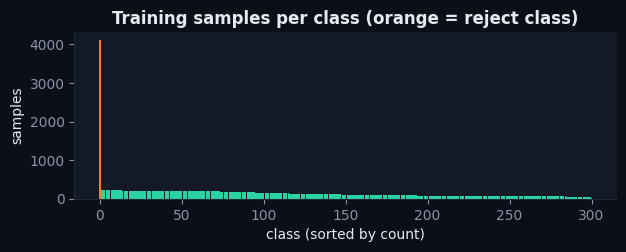

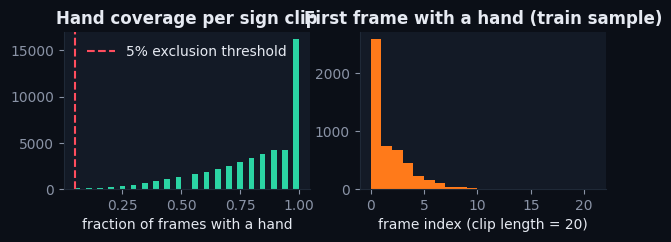

[ok] dataset figures: 0.6s


In [8]:
with step("dataset figures"):
    ytr = META.y[IDX["train"]].values
    cnt = np.bincount(ytr, minlength=N_CLS)
    order = np.argsort(-cnt)
    fig, ax = plt.subplots(figsize=(11, 3.4))
    ax.bar(range(N_CLS), cnt[order], color=[PAL["teal"] if RUN_KEYS[i] != REJECT_KEY else PAL["orange"] for i in order], width=0.9)
    ax.set_title("Training samples per class (orange = reject class)"); ax.set_xlabel("class (sorted by count)"); ax.set_ylabel("samples")
    save_fig(fig, "class_distribution.png")

    fig, axs = plt.subplots(1, 2, figsize=(11, 3.2))
    c = META.hand_coverage[(META.key != REJECT_KEY) & (META.split != "unused")]
    axs[0].hist(c, bins=40, color=PAL["teal"]); axs[0].axvline(0.05, color=PAL["red"], ls="--", label="5% exclusion threshold")
    axs[0].set_title("Hand coverage per sign clip"); axs[0].set_xlabel("fraction of frames with a hand"); axs[0].legend(frameon=False)
    nz = (X16[IDX["train"][:5000]] != 0).any(-1)
    first = np.where(nz.any(1), nz.argmax(1), T)
    axs[1].hist(first, bins=range(0, T + 2), color=PAL["orange"]); axs[1].set_title("First frame with a hand (train sample)"); axs[1].set_xlabel("frame index (clip length = 20)")
    save_fig(fig, "hand_coverage_hist.png")

## 8 · Feature & augmentation checks
Every line prints `PASS` — flip identity, feature shape, determinism, finite values, and that our recomputed velocity matches the dataset's stored velocity on the webcam domain.

PASS - flipping twice is the identity
PASS - feature shape (20, 506)
PASS - build is deterministic


PASS - no NaN / inf in data or augmented batch
PASS - recomputed velocity vs stored velocity (webcam), max abs diff 0.0000


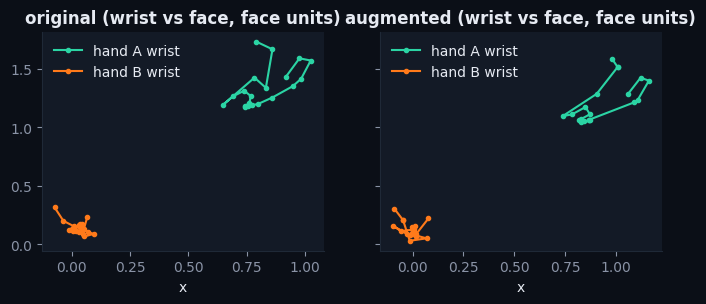

[ok] feature checks: 4.1s


In [9]:
with step("feature checks"):
    import torch
    s = torch.from_numpy(X16[IDX["train"][:64]].astype(np.float32))
    ok = torch.allclose(isl_core.flip_base(isl_core.flip_base(s)), s); print("PASS" if ok else "FAIL", "- flipping twice is the identity"); assert ok
    f1 = isl_core.base_to_features(s[0].numpy()); f2 = isl_core.base_to_features(s[0].numpy())
    ok = f1.shape == (T, N_FEAT); print("PASS" if ok else "FAIL", f"- feature shape {f1.shape}"); assert ok
    ok = np.array_equal(f1, f2); print("PASS" if ok else "FAIL", "- build is deterministic"); assert ok
    bad = 0
    for i in range(0, len(X16), 16384):
        bad += int((~np.isfinite(X16[i:i + 16384].astype(np.float32))).sum())
    aug = augment_base(s.to(DEVICE)); bad += int((~torch.isfinite(aug)).sum())
    ok = bad == 0; print("PASS" if ok else "FAIL", "- no NaN / inf in data or augmented batch"); assert ok
    web = META.index[(META.group == "main_positive") & (META.domain == "webcam")].values[:300]
    with h5py.File(H5, "r") as f:
        stored = np.stack([f["main_positive/data"][int(META.h5_index[i])] for i in web])
    mine = isl_core.base_to_features(stored[:, :, :N_BASE])[:, :, N_BASE:2 * N_BASE]
    err = float(np.abs(mine - stored[:, :, 253:253 + N_BASE]).max())
    ok = err < 0.05; print("PASS" if ok else "FAIL", f"- recomputed velocity vs stored velocity (webcam), max abs diff {err:.4f}"); assert ok
    # visual: original vs augmented hand trajectory
    i0 = IDX["train"][int(np.argmax(META.hand_coverage[IDX["train"]].values))]
    o = torch.from_numpy(X16[i0].astype(np.float32))[None].to(DEVICE)
    torch.manual_seed(1); a = augment_base(o.repeat(3, 1, 1))
    fig, axs = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
    for ax, seq, ttl in ((axs[0], o[0].cpu(), "original"), (axs[1], a[0].cpu(), "augmented")):
        for blk, col in ((2, PAL["teal"]), (3, PAL["orange"])):
            pts = seq.view(T, 4, 21, 3)[:, blk, 0, :2]; m = pts.abs().sum(-1) > 0
            ax.plot(pts[m, 0], pts[m, 1], "-o", ms=3, color=col, label=f"hand {'A' if blk == 2 else 'B'} wrist")
        ax.invert_yaxis(); ax.set_title(f"{ttl} (wrist vs face, face units)"); ax.set_xlabel("x"); ax.legend(frameon=False)
    show_fig(fig, 8)

## 9 · Training
Both models see exactly the same data, features and GPU augmentation (flip, rotation, temporal crop/speed, noise, hand blanking, frame hold, and scale/offset jitter on the face-relative block so the model stays robust to the inferred face reference). AdamW, 10-epoch warm-up + cosine decay, label smoothing 0.1, AMP, gradient clipping, early stopping on validation top-1. A run whose configuration hash matches a saved checkpoint is loaded instead of retrained.

* **Baseline** — 2-layer BiGRU with mean + max pooling.
* **Main model** — 4-layer pre-norm Transformer encoder (d_model 256, 8 heads) with a CLS token.

In [10]:
import random, torch
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False

def to_gpu(idx):
    return (torch.from_numpy(X16[idx].astype(np.float32)).to(DEVICE),
            torch.from_numpy(META.y.values[idx]).to(DEVICE))
XTR, YTR = to_gpu(IDX["train"]); XVA, YVA = to_gpu(IDX["val"])
XTE, YTE = to_gpu(IDX["test"]); XMV, YMV = to_gpu(IDX["test_mvi"])
print({k: tuple(v.shape) for k, v in dict(train=XTR, val=XVA, test=XTE, test_mvi=XMV).items()})

KIND_FILE = {"bigru": "baseline_bigru.pt", "transformer": "signsetu_transformer.pt"}
HP = {"bigru": dict(hidden=192, dropout=0.3), "transformer": dict(d_model=256, heads=8, ff=512, layers=4, dropout=0.3)}
LR = {"bigru": 1e-3, "transformer": 5e-4}
SPLIT_HASH = hashlib.sha256(np.concatenate([IDX["train"], IDX["val"]]).tobytes()).hexdigest()[:12]
TRAIN_RESULT = {}

def make_cfg(kind, batch_size=64):
    return dict(lr=LR[kind], weight_decay=0.05, batch_size=batch_size, max_epochs=3 if SMOKE_TEST else 200,
                warmup=1 if SMOKE_TEST else 10, patience=30, label_smoothing=0.1, seed=SEED, aug={})

def db_run_insert(kind, run_uid, cfg, chash, params, status):
    with isl_core.connect() as conn:
        row = conn.execute("SELECT id FROM training_runs WHERE run_uid=%s", (run_uid,)).fetchone()
        if row:
            conn.execute("DELETE FROM epoch_metrics WHERE run_id=%s", (row[0],)); conn.commit(); return row[0]
        rid = conn.execute("INSERT INTO training_runs (run_uid, model_type, dataset_variant, config, config_hash, device, params, status) "
                           "VALUES (%s,%s,%s,%s,%s,%s,%s,%s) RETURNING id",
                           (run_uid, kind, "SMOKE" if SMOKE_TEST else DATASET_VARIANT, json.dumps(cfg), chash,
                            str(DEVICE) + (" " + torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else ""), params, status)).fetchone()[0]
        conn.commit(); return rid

def db_epochs(run_id, hist):
    with isl_core.connect() as conn:
        conn.execute("DELETE FROM epoch_metrics WHERE run_id=%s", (run_id,))
        conn.cursor().executemany("INSERT INTO epoch_metrics (run_id, epoch, train_loss, train_top1, val_loss, val_top1, val_top5, lr, seconds) "
            "VALUES (%s,%s,%s,%s,%s,%s,%s,%s,%s)", [(run_id, h["epoch"], h["train_loss"], h["train_top1"], h["val_loss"], h["val_top1"], h["val_top5"], h["lr"], h["seconds"]) for h in hist])
        conn.commit()

def train_or_load(kind):
    ckpt_path = MODELS / KIND_FILE[kind]
    cfg = make_cfg(kind)
    chash = isl_core.config_hash(dict(fv=FEATURE_VERSION, variant=DATASET_VARIANT, smoke=SMOKE_TEST, hp=HP[kind], cfg=cfg, split=SPLIT_HASH, n=N_CLS))
    run_uid = f"{'smoke-' if SMOKE_TEST else ''}{kind}-{chash}"
    if ckpt_path.exists() and not FORCE_RETRAIN:
        ck = torch.load(ckpt_path, map_location="cpu", weights_only=False)
        if ck.get("config_hash") == chash:
            print(f"[{kind}] checkpoint matches config hash {chash} - skipping training (best epoch {ck['best_epoch']}, val top-1 {ck['best_val_top1']:.4f})")
            print(f"[{kind}] trained {ck['trained_at']} in {ck['train_minutes']:.1f} min on torch {ck['torch_version']}; saved per-epoch history:")
            for h in ck["history"]:
                if h["epoch"] == 1 or h["epoch"] % 10 == 0 or h["epoch"] == ck["best_epoch"] or h["epoch"] == len(ck["history"]):
                    print(f"    epoch {h['epoch']:3d}  train loss {h['train_loss']:.3f}  val loss {h['val_loss']:.3f}  val top-1 {h['val_top1']:.4f}  lr {h['lr']:.2e}")
            rid = db_run_insert(kind, run_uid, cfg, chash, ck["params"], "completed"); db_epochs(rid, ck["history"])
            with isl_core.connect() as conn:
                conn.execute("UPDATE training_runs SET status='completed', best_epoch=%s, best_val_top1=%s, checkpoint_path=%s, finished_at=now() WHERE id=%s",
                             (ck["best_epoch"], ck["best_val_top1"], str(ckpt_path.relative_to(ROOT)), rid)); conn.commit()
            return ck, rid
    bs = cfg["batch_size"]
    while True:
        cfg = make_cfg(kind, bs)
        torch.manual_seed(SEED)
        model = isl_core.build_model(kind, N_CLS, HP[kind]).to(DEVICE)
        mu, sd = isl_core.compute_norm(XTR); model.set_norm(mu, sd)
        rid = db_run_insert(kind, run_uid, cfg, chash, isl_core.count_params(model), "running")
        hist_live = []
        def on_epoch(rec, _rid=rid):
            hist_live.append(rec)
            if rec["epoch"] % 5 == 0 or rec["epoch"] == 1:
                db_epochs(_rid, hist_live)
        t0 = time.time()
        try:
            hist, best = isl_core.fit(kind, model, XTR, YTR, XVA, YVA, cfg, on_epoch=on_epoch)
            break
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache(); bs //= 2; print(f"CUDA OOM - retrying with batch size {bs}")
            assert bs >= 8
    minutes = (time.time() - t0) / 60
    db_epochs(rid, hist)
    ck = dict(model_type=kind, hparams=HP[kind], state_dict={k: v.cpu() for k, v in model.state_dict().items()},
              classes=RUN_KEYS, config=dict(cfg, tta=False), config_hash=chash, feature_version=FEATURE_VERSION, T=T, n_feat=N_FEAT,
              history=hist, best_epoch=best["epoch"], best_val_top1=best["val_top1"], train_minutes=minutes,
              params=isl_core.count_params(model), torch_version=torch.__version__, trained_at=time.strftime("%Y-%m-%d %H:%M:%S"))
    torch.save(ck, ckpt_path)
    with isl_core.connect() as conn:
        conn.execute("UPDATE training_runs SET status='completed', best_epoch=%s, best_val_top1=%s, checkpoint_path=%s, finished_at=now() WHERE id=%s",
                     (best["epoch"], best["val_top1"], str(ckpt_path.relative_to(ROOT)), rid)); conn.commit()
    print(f"[{kind}] done in {minutes:.1f} min | best epoch {best['epoch']} | val top-1 {best['val_top1']:.4f}")
    return ck, rid

{'train': (41319, 20, 252), 'val': (4732, 20, 252), 'test': (4732, 20, 252), 'test_mvi': (920, 20, 252)}


### 9a · Baseline: BiGRU

In [11]:
with step("train BiGRU baseline"):
    TRAIN_RESULT["bigru"] = train_or_load("bigru")

[bigru] checkpoint matches config hash f3b16fa9eecfe87c - skipping training (best epoch 110, val top-1 0.9884)
[bigru] trained 2026-11-02 14:59:17 in 7.7 min on torch 2.8.0+cu128; saved per-epoch history:
    epoch   1  train loss 5.189  val loss 4.234  val top-1 0.1247  lr 1.00e-04
    epoch  10  train loss 1.226  val loss 0.189  val top-1 0.9643  lr 1.00e-03
    epoch  20  train loss 1.089  val loss 0.142  val top-1 0.9793  lr 9.93e-04
    epoch  30  train loss 1.050  val loss 0.140  val top-1 0.9820  lr 9.73e-04
    epoch  40  train loss 1.028  val loss 0.162  val top-1 0.9784  lr 9.40e-04
    epoch  50  train loss 1.019  val loss 0.151  val top-1 0.9818  lr 8.95e-04
    epoch  60  train loss 1.005  val loss 0.143  val top-1 0.9850  lr 8.39e-04
    epoch  70  train loss 1.000  val loss 0.135  val top-1 0.9867  lr 7.74e-04
    epoch  80  train loss 0.993  val loss 0.140  val top-1 0.9848  lr 7.01e-04
    epoch  90  train loss 0.979  val loss 0.154  val top-1 0.9844  lr 6.23e-04
    e

### 9b · Main model: Transformer encoder

In [12]:
with step("train Transformer"):
    TRAIN_RESULT["transformer"] = train_or_load("transformer")

[transformer] checkpoint matches config hash b89a364b3bb14bd7 - skipping training (best epoch 171, val top-1 0.9896)
[transformer] trained 2026-11-02 15:14:49 in 15.5 min on torch 2.8.0+cu128; saved per-epoch history:
    epoch   1  train loss 5.393  val loss 4.353  val top-1 0.1805  lr 5.00e-05
    epoch  10  train loss 1.328  val loss 0.181  val top-1 0.9596  lr 5.00e-04
    epoch  20  train loss 1.130  val loss 0.119  val top-1 0.9757  lr 4.97e-04
    epoch  30  train loss 1.079  val loss 0.105  val top-1 0.9774  lr 4.86e-04
    epoch  40  train loss 1.052  val loss 0.094  val top-1 0.9827  lr 4.70e-04
    epoch  50  train loss 1.032  val loss 0.090  val top-1 0.9831  lr 4.47e-04
    epoch  60  train loss 1.019  val loss 0.093  val top-1 0.9812  lr 4.19e-04
    epoch  70  train loss 1.010  val loss 0.103  val top-1 0.9816  lr 3.87e-04
    epoch  80  train loss 0.997  val loss 0.086  val top-1 0.9848  lr 3.51e-04
    epoch  90  train loss 0.994  val loss 0.089  val top-1 0.9852  lr 3

## 10 · Evaluation
Held-out numbers only — the test splits are touched once, here. Headline metrics are over **sign clips** (a prediction of `Not a sign` counts as an error); we also report reject-class recall, the false-reject rate, and the **cross-domain score on the MVI hold-out**. Test-time augmentation (average with the mirrored sequence) is enabled in the app only if it improves *validation* top-1 by ≥ 0.5 pp.

In [13]:
from sklearn.metrics import f1_score, precision_recall_fscore_support, balanced_accuracy_score
SIGN_LABELS = list(range(REJ))
CAT = np.array([isl_core.category_of(k) for k in RUN_KEYS])
GLOSS = np.array([isl_core.display_gloss(k) for k in RUN_KEYS])
EVAL = {}

def sign_metrics(P, y):
    y = y.cpu().numpy() if torch.is_tensor(y) else y
    P = P.numpy() if torch.is_tensor(P) else P
    pred = P.argmax(1); m = y != REJ
    top5 = np.argsort(-P, 1)[:, :5]
    out = dict(top1=float((pred[m] == y[m]).mean()), top5=float((top5[m] == y[m][:, None]).any(1).mean()),
               macro_f1=float(f1_score(y[m], pred[m], labels=SIGN_LABELS, average="macro", zero_division=0)),
               balanced_acc=float(balanced_accuracy_score(y[m], pred[m])), n=int(m.sum()))
    if (~m).any():
        out["reject_recall"] = float((pred[~m] == REJ).mean())
    out["false_reject_rate"] = float((pred[m] == REJ).mean())
    return out

with step("evaluation"):
    for kind in ("bigru", "transformer"):
        ck, rid = TRAIN_RESULT[kind]
        model = isl_core.build_model(kind, N_CLS, HP[kind]).to(DEVICE); model.load_state_dict(ck["state_dict"]); model.eval()
        pv0, pv1 = isl_core.predict_proba(model, XVA), isl_core.predict_proba(model, XVA, tta=True)
        v0, v1 = sign_metrics(pv0, YVA)["top1"], sign_metrics(pv1, YVA)["top1"]
        use_tta = (v1 - v0) >= 0.005
        ck["config"]["tta"] = bool(use_tta)
        torch.save(ck, MODELS / KIND_FILE[kind])
        P = {s: isl_core.predict_proba(model, X, tta=False) for s, X in (("test", XTE), ("test_mvi", XMV))}
        Pt = {s: isl_core.predict_proba(model, X, tta=True) for s, X in (("test", XTE), ("test_mvi", XMV))}
        r = dict(test=sign_metrics(P["test"], YTE), test_tta=sign_metrics(Pt["test"], YTE),
                 cross_domain=sign_metrics(P["test_mvi"], YMV), cross_domain_tta=sign_metrics(Pt["test_mvi"], YMV),
                 val_top1=v0, val_top1_tta=v1, tta_enabled=bool(use_tta), params=ck["params"], best_epoch=ck["best_epoch"],
                 train_minutes=round(ck["train_minutes"], 2), P=P, rid=rid)
        EVAL[kind] = r
        # per-class metrics on the in-domain test set (incl. reject class)
        yt = YTE.cpu().numpy(); pr = P["test"].argmax(1).numpy()
        p, rc, f1, sup = precision_recall_fscore_support(yt, pr, labels=list(range(N_CLS)), zero_division=0)
        r["class_df"] = pd.DataFrame(dict(class_index=range(N_CLS), key=RUN_KEYS, gloss=GLOSS, category=CAT, precision=p, recall=rc, f1=f1, support=sup))
        with isl_core.connect() as conn:
            conn.execute("DELETE FROM class_metrics WHERE run_id=%s", (rid,))
            conn.cursor().executemany("INSERT INTO class_metrics (run_id, vocab_id, precision, recall, f1, support) VALUES (%s,%s,%s,%s,%s,%s)",
                [(rid, VOCAB_ID[k], float(a), float(b), float(c), int(d)) for k, a, b, c, d in zip(RUN_KEYS, p, rc, f1, sup)])
            conn.execute("UPDATE training_runs SET test_top1=%s, test_top5=%s, test_macro_f1=%s, test_top1_tta=%s WHERE id=%s",
                         (r["test"]["top1"], r["test"]["top5"], r["test"]["macro_f1"], r["test_tta"]["top1"], rid)); conn.commit()
        print(f"{kind:12s} test top-1 {r['test']['top1']:.4f} | top-5 {r['test']['top5']:.4f} | macro-F1 {r['test']['macro_f1']:.4f} | "
              f"top-1+TTA {r['test_tta']['top1']:.4f} | cross-domain (MVI) top-1 {r['cross_domain']['top1']:.4f} | TTA used in app: {use_tta}")

    # per-category accuracy, confused pairs (Transformer, in-domain test, sign clips)
    TR = EVAL["transformer"]; yt = YTE.cpu().numpy(); pr = TR["P"]["test"].argmax(1).numpy(); msk = yt != REJ
    cat_acc = {c: float((pr[msk & (CAT[yt] == c)] == yt[msk & (CAT[yt] == c)]).mean()) for c in dict.fromkeys(CAT) if c != "Reject" and (msk & (CAT[yt] == c)).any()}
    wrong = pd.Series(list(zip(yt[msk & (pr != yt)], pr[msk & (pr != yt)]))).value_counts().head(15)
    CONFUSED = [dict(true=str(GLOSS[a]), pred=str(GLOSS[b]), count=int(n)) for (a, b), n in wrong.items()]
    print(pd.DataFrame(CONFUSED).to_string(index=False))

bigru        test top-1 0.9859 | top-5 0.9978 | macro-F1 0.9873 | top-1+TTA 0.9857 | cross-domain (MVI) top-1 0.8163 | TTA used in app: False


transformer  test top-1 0.9879 | top-5 0.9978 | macro-F1 0.9884 | top-1+TTA 0.9872 | cross-domain (MVI) top-1 0.8554 | TTA used in app: False
      true       pred  count
      Good       Nice     11
       His        Him      7
      Nice       Good      5
       Him        His      2
Climb Down   Yourself      1
         2          V      1
     Blind        She      1
    Famous       Dead      1
    Famous       Poor      1
    Famous       Thin      1
      Cool Not a sign      1
     Happy  Expensive      1
      Flat        She      1
        He      Quiet      1
        He        She      1
[ok] evaluation: 2.4s


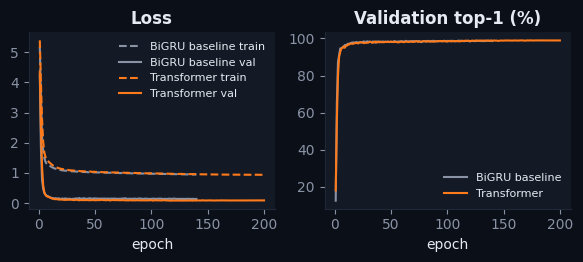

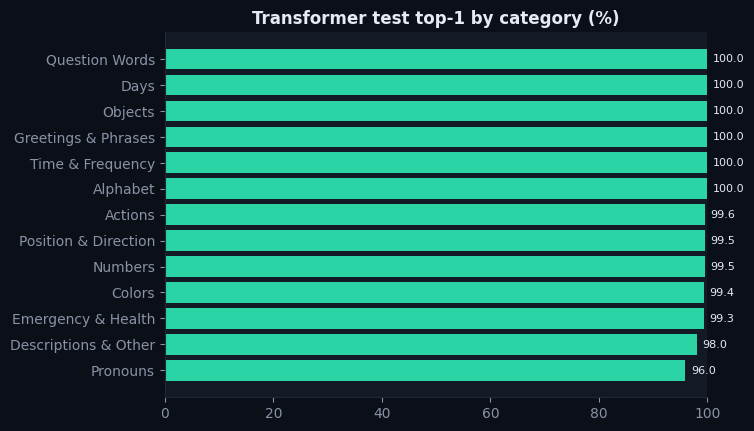

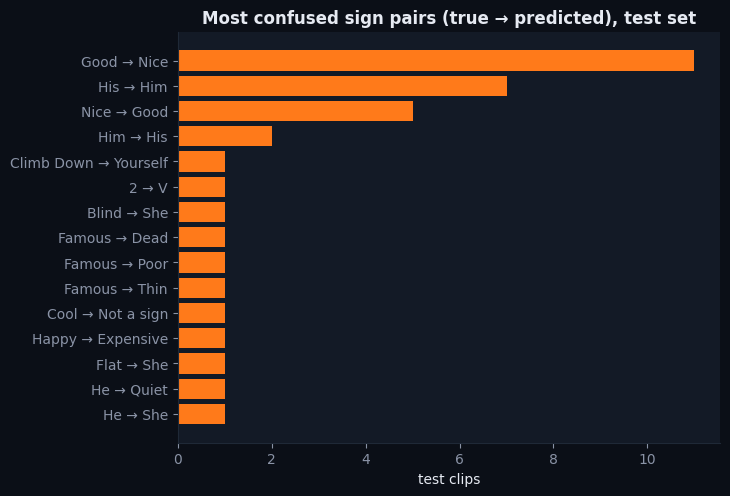

[ok] evaluation figures: 0.4s


In [14]:
with step("evaluation figures"):
    # training curves
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
    for kind, col, nm in (("bigru", PAL["muted"], "BiGRU baseline"), ("transformer", PAL["orange"], "Transformer")):
        h = pd.DataFrame(TRAIN_RESULT[kind][0]["history"])
        axs[0].plot(h.epoch, h.train_loss, color=col, ls="--", label=f"{nm} train"); axs[0].plot(h.epoch, h.val_loss, color=col, label=f"{nm} val")
        axs[1].plot(h.epoch, h.val_top1 * 100, color=col, label=nm)
    axs[0].set_title("Loss"); axs[0].set_xlabel("epoch"); axs[0].legend(frameon=False, fontsize=8)
    axs[1].set_title("Validation top-1 (%)"); axs[1].set_xlabel("epoch"); axs[1].legend(frameon=False, fontsize=8)
    save_fig(fig, "training_curves.png")
    # per-category accuracy
    cats = sorted(cat_acc, key=cat_acc.get)
    fig, ax = plt.subplots(figsize=(8, 0.34 * len(cats) + 1))
    ax.barh(cats, [cat_acc[c] * 100 for c in cats], color=PAL["teal"]); ax.set_xlim(0, 100)
    for i, c in enumerate(cats):
        ax.text(cat_acc[c] * 100 + 1, i, f"{cat_acc[c]*100:.1f}", va="center", fontsize=8, color=PAL["text"])
    ax.set_title("Transformer test top-1 by category (%)"); save_fig(fig, "per_category_accuracy.png")
    # confused pairs
    cp = pd.DataFrame(CONFUSED)[::-1]
    fig, ax = plt.subplots(figsize=(8, 0.34 * len(cp) + 1))
    ax.barh([f"{a} → {b}" for a, b in zip(cp.true, cp.pred)], cp["count"], color=PAL["orange"])
    ax.set_title("Most confused sign pairs (true → predicted), test set"); ax.set_xlabel("test clips")
    save_fig(fig, "confused_pairs.png")

## 11 · ONNX export and latency
The Transformer (input normalisation included) is exported to ONNX (opset 17, dynamic batch). We check parity with PyTorch and benchmark single-sample latency on CUDA, CPU and ONNX Runtime, plus MediaPipe Holistic per-frame cost on CPU at 640 px.

In [15]:
import onnx, onnxruntime as ort
with step("ONNX export + parity + latency"):
    ck = TRAIN_RESULT["transformer"][0]
    cpu_model = isl_core.build_model("transformer", N_CLS, HP["transformer"]); cpu_model.load_state_dict(ck["state_dict"]); cpu_model.eval()
    ONNX_PATH = MODELS / "signsetu_transformer.onnx"
    torch.onnx.export(cpu_model, torch.randn(2, T, N_FEAT), str(ONNX_PATH), input_names=["features"], output_names=["logits"],
                      dynamic_axes={"features": {0: "batch"}, "logits": {0: "batch"}}, opset_version=17, dynamo=False)
    onnx.checker.check_model(onnx.load(str(ONNX_PATH)))
    sess = ort.InferenceSession(str(ONNX_PATH), providers=["CPUExecutionProvider"])
    fv = isl_core.base_to_features(XVA[:32].cpu().numpy())
    d = float(np.abs(sess.run(["logits"], {"features": fv})[0] - cpu_model(torch.from_numpy(fv)).detach().numpy()).max())
    print("PASS" if d < 1e-3 else "FAIL", f"- ONNX vs PyTorch max abs diff {d:.2e}"); assert d < 1e-3

    x1 = isl_core.base_to_features(XVA[:1].cpu().numpy())
    def bench(fn, n=200, warm=20):
        for _ in range(warm): fn()
        ts = []
        for _ in range(n):
            t0 = time.perf_counter(); fn(); ts.append((time.perf_counter() - t0) * 1000)
        return dict(mean=float(np.mean(ts)), p95=float(np.percentile(ts, 95)))
    LAT = {}
    if DEVICE.type == "cuda":
        gm = isl_core.build_model("transformer", N_CLS, HP["transformer"]).to(DEVICE); gm.load_state_dict(ck["state_dict"]); gm.eval()
        xg = torch.from_numpy(x1).to(DEVICE)
        def f_gpu():
            with torch.no_grad(): gm(xg); torch.cuda.synchronize()
        LAT["torch_cuda_ms"] = bench(f_gpu)
    torch.set_num_threads(max(1, HW["physical_cores"] - 1)); xc = torch.from_numpy(x1)
    def f_cpu():
        with torch.no_grad(): cpu_model(xc)
    LAT["torch_cpu_ms"] = bench(f_cpu)
    LAT["onnx_cpu_ms"] = bench(lambda: sess.run(["logits"], {"features": x1}))
    # MediaPipe Holistic cost per frame (CPU, 640 px)
    import cv2
    BENCH = ROOT / "data" / "bench.webm"
    if not BENCH.exists():
        try:
            import requests
            t = "File:Armenian Sign Language (ArSL) - նոր - new.webm"
            u = requests.get("https://commons.wikimedia.org/w/api.php", params=dict(action="query", titles=t, prop="imageinfo", iiprop="url", format="json"),
                             headers={"User-Agent": "SignSetu/1.0"}, timeout=30).json()["query"]["pages"]
            url = list(u.values())[0]["imageinfo"][0]["url"]
            BENCH.write_bytes(requests.get(url, headers={"User-Agent": "SignSetu/1.0"}, timeout=120).content)
        except Exception as e:
            print("benchmark clip unavailable:", e)
    frames, bench_src = [], "synthetic frame"
    if BENCH.exists():
        cap = cv2.VideoCapture(str(BENCH))
        while len(frames) < 300:
            ok, fr = cap.read()
            if not ok: break
            h, w = fr.shape[:2]; s = 640 / max(h, w)
            fr = cv2.resize(fr, (int(w * s), int(h * s)), interpolation=cv2.INTER_AREA)
            frames.append(cv2.cvtColor(cv2.flip(fr, 1), cv2.COLOR_BGR2RGB))
        cap.release()
        bench_src = "CC BY-SA 4.0 sign-language clip (Wikimedia Commons), 1080p resized to 640 px"
    if not frames:
        frames = [np.random.default_rng(0).integers(0, 255, (480, 640, 3), dtype=np.uint8)] * 120
    ex = isl_core.LiveExtractor()
    for fr in frames[:10]: ex.process(fr)
    t0 = time.perf_counter()
    for fr in frames: ex.process(fr)
    HOL_MS = (time.perf_counter() - t0) * 1000 / len(frames); ex.close()
    best_model_ms = min(v["mean"] for k, v in LAT.items())
    LAT["holistic_ms_per_frame"] = HOL_MS; LAT["holistic_benchmark_input"] = bench_src
    LAT["est_fps"] = 1000.0 / (HOL_MS + best_model_ms)
    print(json.dumps({k: (round(v, 2) if isinstance(v, float) else v) for k, v in LAT.items()}, indent=1, default=lambda o: {a: round(b, 2) for a, b in o.items()}))

PASS - ONNX vs PyTorch max abs diff 6.68e-06


Truncating packet of size 3907 to 1960
[matroska,webm @ 0x5602591d2bc0] EBML header parsing failed
I0000 00:00:1793617341.721473  337753 gl_context_egl.cc:85] Successfully initialized EGL. Major : 1 Minor: 5
I0000 00:00:1793617341.727876  338191 gl_context.cc:369] GL version: 3.2 (OpenGL ES 3.2 Mesa 26.2.5), renderer: AMD Radeon 780M Graphics (radeonsi, phoenix, ACO, DRM 3.64, 7.2.13-200.fc44.x86_64)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1793617341.769906  338166 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1793617341.799503  338179 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1793617341.802321  338166 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback ten

{
 "torch_cuda_ms": {
  "mean": 0.6444395350081322,
  "p95": 0.7290156519957233
 },
 "torch_cpu_ms": {
  "mean": 0.9492356500413734,
  "p95": 1.2824199005990522
 },
 "onnx_cpu_ms": {
  "mean": 0.6337756400898797,
  "p95": 0.8789727013208902
 },
 "holistic_ms_per_frame": 10.46,
 "holistic_benchmark_input": "CC BY-SA 4.0 sign-language clip (Wikimedia Commons), 1080p resized to 640 px",
 "est_fps": 90.16
}
[ok] ONNX export + parity + latency: 2.4s


## 12 · Reports: `label_map.json`, `metrics.json`, `classification_report.csv`

In [16]:
with step("write reports"):
    label_map = {str(i): dict(gloss=str(GLOSS[i]), category=str(CAT[i]), class_key=k, hindi=isl_core.HINDI[k]) for i, k in enumerate(RUN_KEYS)}
    (MODELS / "label_map.json").write_text(json.dumps(label_map, ensure_ascii=False, indent=1), encoding="utf-8")
    EVAL["transformer"]["class_df"].to_csv(REPORTS / "classification_report.csv", index=False)
    with isl_core.connect() as conn:
        ext = dict(conn.execute("SELECT split, count(*) FROM samples WHERE split<>'unused' GROUP BY split").fetchall())
    def mod(kind):
        r = EVAL[kind]
        return dict(top1=r["test"]["top1"], top5=r["test"]["top5"], macro_f1=r["test"]["macro_f1"], balanced_acc=r["test"]["balanced_acc"],
                    top1_tta=r["test_tta"]["top1"], reject_recall=r["test"].get("reject_recall"), false_reject_rate=r["test"]["false_reject_rate"],
                    cross_domain_top1=r["cross_domain"]["top1"], cross_domain_top1_tta=r["cross_domain_tta"]["top1"], cross_domain_n=r["cross_domain"]["n"],
                    tta_enabled=r["tta_enabled"], params=r["params"], best_epoch=r["best_epoch"], train_minutes=r["train_minutes"])
    METRICS = dict(dataset_variant="SMOKE" if SMOKE_TEST else DATASET_VARIANT, num_classes=N_CLS, num_sign_classes=N_CLS - 1,
        split_sizes=dict(train=len(IDX["train"]), val=len(IDX["val"]), test=len(IDX["test"]), test_mvi=len(IDX["test_mvi"])),
        models=dict(bigru=mod("bigru"), transformer=mod("transformer")),
        per_category={c: round(v, 4) for c, v in cat_acc.items()}, confused_pairs=CONFUSED,
        latency=LAT, hardware=HW,
        extraction=dict(clips_total=int(len(META)), clips_used=int(sum(len(v) for v in IDX.values())),
                        excluded=META.reason[META.reason != ""].value_counts().to_dict(), source="precomputed features (no video extraction)"),
        published_baseline=None, generated_at=time.strftime("%Y-%m-%d %H:%M:%S"))
    (REPORTS / "metrics.json").write_text(json.dumps(METRICS, indent=1, default=float), encoding="utf-8")
    print("wrote", (REPORTS / "metrics.json").relative_to(ROOT), "and", (MODELS / "label_map.json").relative_to(ROOT))
    # compact held-out test clips for the app's "Test samples" tab (1-2 per class)
    rows, seqs, doms = [], [], []
    for ci in range(N_CLS):
        for j in np.where(META.y.values[IDX["test"]] == ci)[0][:2]:
            rows.append(ci); seqs.append(X16[IDX["test"][j]]); doms.append("in-domain test")
    for ci in range(N_CLS):          # plus one cross-domain clip per class when available
        for j in np.where(META.y.values[IDX["test_mvi"]] == ci)[0][:1]:
            rows.append(ci); seqs.append(X16[IDX["test_mvi"][j]]); doms.append("cross-domain (MVI)")
    np.savez_compressed(MODELS / "demo_samples.npz", labels=np.array(rows), base=np.stack(seqs).astype(np.float16), domain=np.array(doms))
    print("demo samples:", len(rows), "| size", round((MODELS / "demo_samples.npz").stat().st_size / 1e6, 1), "MB")

wrote reports/metrics.json and models/label_map.json
demo samples: 650 | size 3.4 MB
[ok] write reports: 0.1s


## 13 · Demo GIF
Rendered from **real test-set predictions** of the Transformer: four correctly-classified clips from four different categories, drawn from the stored landmark features (hands positioned relative to the face).

In [17]:
from PIL import Image, ImageDraw, ImageFont, features as pil_features
import imageio.v2 as imageio
import mediapipe as mp
with step("demo GIF"):
    CONN = list(mp.solutions.hands.HAND_CONNECTIONS)
    def font(sz, deva=False):
        paths = (["/usr/share/fonts/google-noto-vf/NotoSansDevanagari[wght].ttf", "/usr/share/fonts/google-droid-sans-fonts/DroidSansDevanagari-Regular.ttf",
                  "C:/Windows/Fonts/Nirmala.ttf"] if deva else
                 ["/usr/share/fonts/google-noto/NotoSans-Regular.ttf", "/usr/share/fonts/dejavu-sans-fonts/DejaVuSans.ttf", "C:/Windows/Fonts/segoeui.ttf"])
        for p in paths:
            if Path(p).exists():
                try:
                    return ImageFont.truetype(p, sz, layout_engine=ImageFont.Layout.RAQM if pil_features.check("raqm") else ImageFont.Layout.BASIC)
                except Exception:
                    pass
        return ImageFont.load_default()
    pred_all = EVAL["transformer"]["P"]["test"]; yt = YTE.cpu().numpy(); pr = pred_all.argmax(1).numpy(); conf = pred_all.max(1).values.numpy()
    cov_te = META.hand_coverage.values[IDX["test"]]
    cand = [i for i in range(len(yt)) if yt[i] != REJ and pr[i] == yt[i] and conf[i] > 0.9 and cov_te[i] > 0.7]
    chosen, seen = [], set()
    for want in ("Greetings & Phrases", "Days", "Emergency & Health", "Colors", "Pronouns", "Alphabet", "Numbers", "Actions", "Descriptions & Other"):
        for i in cand:
            if CAT[yt[i]] == want and want not in seen:
                chosen.append(i); seen.add(want); break
        if len(chosen) == 4: break
    for i in cand:
        if len(chosen) >= 4: break
        if i not in chosen and CAT[yt[i]] not in seen:
            chosen.append(i); seen.add(CAT[yt[i]])
    W, H, SC, ORG = 480, 400, 50.0, (240, 62)
    def frame_img(seq, gt, pd_, cf, step_i):
        im = Image.new("RGB", (W, H), PAL["bg"]); dr = ImageDraw.Draw(im)
        dr.rectangle([0, 0, W, 300], fill=PAL["panel"])
        ox, oy = ORG
        dr.ellipse([ox - 42, oy - 70, ox + 42, oy + 75], outline="#3B475C", width=2)
        for ex_ in (-25, 25): dr.ellipse([ox + ex_ - 4, oy - 22, ox + ex_ + 4, oy - 14], fill="#3B475C")
        dr.line([ox - 14, oy + 42, ox + 14, oy + 42], fill="#3B475C", width=2)
        dr.text((12, 10), "SignSetu", font=font(16), fill=PAL["orange"]); dr.text((12, 30), "landmark replay (hands vs face)", font=font(11), fill=PAL["muted"])
        pts = seq.reshape(4, 21, 3)
        for blk, colr in ((2, PAL["teal"]), (3, PAL["orange"])):
            h = pts[blk]
            if np.abs(h).sum() == 0: continue
            xy = [(ox + p[0] * SC, oy + p[1] * SC) for p in h]
            for a, b in CONN: dr.line([xy[a], xy[b]], fill=colr, width=2)
            for p in xy: dr.ellipse([p[0] - 2.5, p[1] - 2.5, p[0] + 2.5, p[1] + 2.5], fill=colr)
        dr.text((12, 308), f"Predicted: {GLOSS[pd_].upper()} · {cf*100:.1f}%   |   Ground truth: {GLOSS[gt].upper()}", font=font(17), fill=PAL["text"])
        dr.text((12, 340), isl_core.HINDI[RUN_KEYS[pd_]], font=font(30, True), fill=PAL["teal"])
        dr.text((W - 150, 372), f"{CAT[gt]}", font=font(11), fill=PAL["muted"])
        return np.asarray(im)
    imgs = []
    for i in chosen:
        seq = X16[IDX["test"][i]].astype(np.float32)
        for t in range(T): imgs.append(frame_img(seq[t], yt[i], pr[i], conf[i], t))
        imgs += [imgs[-1]] * 6
    GIF = ROOT / "assets" / ("demo_smoke.gif" if SMOKE_TEST else "demo.gif")
    imageio.mimsave(GIF, imgs, duration=1 / 12, loop=0)
    mb = GIF.stat().st_size / 1e6
    if mb > 8:   # shrink if too big
        imageio.mimsave(GIF, [im[::2, ::2] for im in imgs], duration=1 / 12, loop=0); mb = GIF.stat().st_size / 1e6
    print(f"{GIF.name}: {len(imgs)} frames, {mb:.1f} MB, clips: {[GLOSS[yt[i]] for i in chosen]}")
    assert mb < 8

demo.gif: 104 frames, 0.3 MB, clips: ['Alright', 'Friday', 'Accident', 'Black']
[ok] demo GIF: 2.1s


## 14 · README metrics block

In [18]:
with step("update README metrics block"):
    m = METRICS; tf, bg = m["models"]["transformer"], m["models"]["bigru"]; L = m["latency"]
    pc = lambda x: f"{x*100:.2f}%"
    block = f"""<!-- METRICS:START -->
_Auto-generated by `SignSetu.ipynb` from `reports/metrics.json` ({m['generated_at']}). Hardware: {m['hardware']['gpu']}, {m['hardware']['cpu']}._

**Data used:** {m['num_sign_classes']} sign classes + 1 reject class · train {m['split_sizes']['train']:,} · val {m['split_sizes']['val']:,} · in-domain test {m['split_sizes']['test']:,} · cross-domain test (MVI) {m['split_sizes']['test_mvi']:,}

| Model | Params | Test top-1 | Test top-5 | Macro-F1 | Balanced acc. | Top-1 + TTA | Cross-domain top-1 (MVI) |
|---|---:|---:|---:|---:|---:|---:|---:|
| BiGRU baseline | {bg['params']/1e6:.2f} M | {pc(bg['top1'])} | {pc(bg['top5'])} | {pc(bg['macro_f1'])} | {pc(bg['balanced_acc'])} | {pc(bg['top1_tta'])} | {pc(bg['cross_domain_top1'])} |
| **Transformer (SignSetu)** | {tf['params']/1e6:.2f} M | **{pc(tf['top1'])}** | **{pc(tf['top5'])}** | **{pc(tf['macro_f1'])}** | **{pc(tf['balanced_acc'])}** | {pc(tf['top1_tta'])} | **{pc(tf['cross_domain_top1'])}** |

Transformer reject-class recall: {pc(tf['reject_recall'])} · false-reject rate on sign clips: {pc(tf['false_reject_rate'])} · TTA enabled in app: {'yes' if tf['tta_enabled'] else 'no'} · trained {tf['train_minutes']:.1f} min (best epoch {tf['best_epoch']}).

**Per-category test top-1 (Transformer):**

| Category | Top-1 |
|---|---:|
""" + "\n".join(f"| {c} | {v*100:.1f}% |" for c, v in sorted(m['per_category'].items(), key=lambda kv: -kv[1])) + f"""

**Latency** (single sample, {m['hardware']['cpu']}; GPU {m['hardware']['gpu']}):

| Stage | Mean | p95 |
|---|---:|---:|
""" + "\n".join(f"| {nm} | {L[k]['mean']:.2f} ms | {L[k]['p95']:.2f} ms |" for nm, k in (("Transformer · PyTorch CUDA", "torch_cuda_ms"), ("Transformer · PyTorch CPU", "torch_cpu_ms"), ("Transformer · ONNX Runtime CPU", "onnx_cpu_ms")) if k in L) + f"""
| MediaPipe Holistic · CPU, 640 px | {L['holistic_ms_per_frame']:.1f} ms / frame | — |

Estimated end-to-end real-time rate ≈ **{L['est_fps']:.0f} FPS** (Holistic + best model path). Holistic benchmark input: {L['holistic_benchmark_input']}.
<!-- METRICS:END -->"""
    if SMOKE_TEST:
        print("SMOKE_TEST: README untouched. Preview:\n", block[:600])
    else:
        rd = (ROOT / "README.md").read_text(encoding="utf-8")
        new = re.sub(r"<!-- METRICS:START -->.*?<!-- METRICS:END -->", lambda _m: block, rd, flags=re.S)
        assert new != rd or block in rd
        (ROOT / "README.md").write_text(new, encoding="utf-8"); print("README metrics block updated")

README metrics block updated
[ok] update README metrics block: 0.0s


## 15 · Streamlit app
`app.py` and `.streamlit/config.toml` are generated here. The app has six tabs — Live Translate, Video Upload, Test Samples, Model Report, Vocabulary, History — and logs every prediction to PostgreSQL (if the database goes down, translation keeps working).

In [19]:
%%writefile app.py
# AUTO-GENERATED by SignSetu.ipynb — edit the notebook, not this file.
"""SignSetu — Streamlit UI: live translate, video upload, test samples, model report, vocabulary, history."""
import json
import os
import sys
import tempfile
import time
import uuid
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import streamlit as st
from PIL import Image, ImageDraw

ROOT = Path(__file__).resolve().parent
sys.path.insert(0, str(ROOT))
from dotenv import load_dotenv

load_dotenv(ROOT / ".env")
import isl_core

st.set_page_config(page_title="SignSetu — ISL Translator", page_icon="🤟", layout="wide")

CKPT = ROOT / "models" / "signsetu_transformer.pt"
ONNX = ROOT / "models" / "signsetu_transformer.onnx"
LABELS = ROOT / "models" / "label_map.json"
DEMO = ROOT / "models" / "demo_samples.npz"
METRICS = ROOT / "reports" / "metrics.json"
BG, PANEL, BORDER, TEXT, MUTED = "#0B0F17", "#131A26", "#1F2937", "#E6EAF2", "#8A93A6"
ORANGE, TEAL, AMBER, RED = "#FF7A1A", "#2BD4A4", "#FFB020", "#FF4D5E"
st.markdown(f"""
<link href="https://fonts.googleapis.com/css2?family=Inter:wght@400;500;600;700&family=JetBrains+Mono:wght@500;700&display=swap" rel="stylesheet">
<style>
html, body, [class*="css"], .stMarkdown, button, input {{ font-family: 'Inter','Segoe UI',system-ui,sans-serif; }}
.mono {{ font-family: 'JetBrains Mono', Consolas, monospace; }}
.card {{ background:{PANEL}; border:1px solid {BORDER}; border-radius:14px; padding:16px; margin-bottom:12px; }}
.pred-word {{ font-size:44px; font-weight:700; color:{ORANGE}; line-height:1.1; }}
.pred-hi {{ font-size:28px; color:{TEAL}; }}
.muted {{ color:{MUTED}; }}
.chip {{ display:inline-block; background:{PANEL}; border:1px solid {BORDER}; border-radius:999px; padding:4px 12px; margin-right:8px; font-size:13px; }}
.chip b {{ color:{TEXT}; }}
.pill {{ display:inline-block; border-radius:999px; padding:3px 12px; font-size:12px; font-weight:700; letter-spacing:.04em; color:#0B0F17; }}
.bar-wrap {{ background:{BORDER}; border-radius:6px; height:8px; width:100%; }}
.bar {{ height:8px; border-radius:6px; background:{ORANGE}; }}
.kpi {{ font-size:28px; font-weight:700; }}
.st-key-page [role="radiogroup"] {{ gap:6px; border-bottom:1px solid {BORDER}; padding-bottom:8px; flex-wrap:wrap; }}
.st-key-page label {{ background:{PANEL}; border:1px solid {BORDER}; border-radius:10px; padding:6px 14px; margin:0; cursor:pointer; }}
.st-key-page label > div:first-child {{ display:none; }}
.st-key-page label:has(input:checked) {{ border-color:{ORANGE}; background:rgba(255,122,26,.12); }}
.st-key-page label:has(input:checked) p {{ color:{ORANGE}; font-weight:600; }}
.top5 {{ display:flex; align-items:center; gap:10px; margin:5px 0; font-size:14px; }}
.top5 .n {{ width:130px; overflow:hidden; text-overflow:ellipsis; white-space:nowrap; }}
.top5 .b {{ flex:1; }} .top5 .p {{ width:52px; text-align:right; }}
</style>""", unsafe_allow_html=True)


def log(msg):
    print(f"[signsetu {time.strftime('%H:%M:%S')}] {msg}", file=sys.stderr, flush=True)


# ---------------------------------------------------------------------------------------------- resources
if not CKPT.exists():
    st.markdown(f"<div class='card' style='max-width:520px;margin:15vh auto;text-align:center'>"
                f"<div style='font-size:42px'>🤟</div><h3>Model not found</h3>"
                f"<p class='muted'>Open <b>SignSetu.ipynb</b> and <b>Run All</b>.</p></div>", unsafe_allow_html=True)
    st.stop()


@st.cache_resource(show_spinner="Loading model…")
def get_predictor(engine):
    return isl_core.Predictor(str(CKPT), engine=engine, onnx_path=str(ONNX))


@st.cache_resource
def get_pool():
    try:
        return isl_core.make_pool()
    except Exception as e:
        log(f"DB pool unavailable: {e}")
        return None


@st.cache_data
def load_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8")) if Path(path).exists() else None


LABEL_MAP = load_json(str(LABELS))
METR = load_json(str(METRICS))
NCLS = len(LABEL_MAP)
REJ = NCLS - 1
GLOSS = [LABEL_MAP[str(i)]["gloss"] for i in range(NCLS)]
HINDI = [LABEL_MAP[str(i)]["hindi"] for i in range(NCLS)]
CATEG = [LABEL_MAP[str(i)]["category"] for i in range(NCLS)]
N_SIGNS = NCLS - 1
DISCLAIMER = (f"SignSetu recognises {N_SIGNS} isolated Indian Sign Language signs (words, letters and digits) from the Vāksetu ISL Feature "
              "Dataset. It is an assistive prototype, not a certified interpreter. Video frames are processed locally on this device and "
              "never stored; only predicted words, confidence scores and saved transcripts are logged to the local PostgreSQL database.")


@st.cache_resource
def _db_state():
    return {"down_until": 0.0}


def db(sql, params=None, fetch=False):
    """Run one statement; never raises. Returns rows (fetch) / True, or None when the DB is unavailable.
    After a failure the DB is skipped for 20 s so a dead database cannot slow every rerun."""
    pool = get_pool()
    state = _db_state()
    if pool is None or time.time() < state["down_until"]:
        st.session_state["db_offline"] = True
        return None
    try:
        with pool.connection(timeout=3) as conn:
            cur = conn.execute(sql, params)
            rows = cur.fetchall() if fetch else True
        st.session_state["db_offline"] = False
        return rows
    except Exception as e:
        st.session_state["db_offline"] = True
        state["down_until"] = time.time() + 20
        log(f"DB error: {str(e)[:200]}")
        return None


@st.cache_data(ttl=60)
def vocab_ids():
    rows = db("SELECT class_index, id FROM vocabulary", fetch=True)
    return dict(rows) if rows else {}


@st.cache_data(ttl=60)
def model_run_id():
    rows = db("SELECT id FROM training_runs WHERE model_type='transformer' AND status='completed' AND dataset_variant<>'SMOKE' "
              "ORDER BY finished_at DESC LIMIT 1", fetch=True)
    return rows[0][0] if rows else None


def ensure_session(mode, engine, device):
    key = f"sid_{mode}"
    if key not in st.session_state:
        sid = str(uuid.uuid4())
        if db("INSERT INTO app_sessions (id, mode, engine, device, model_run_id) VALUES (%s,%s,%s,%s,%s)",
              (sid, mode, engine, device, model_run_id())):
            st.session_state[key] = sid
        else:
            return None
    return st.session_state[key]


def log_prediction(source, probs, accepted, n_frames, lm_ms, model_ms, engine, device, corrected=False, truth=None, session_mode=None):
    sid = ensure_session(session_mode or source, engine, device)
    if not sid:
        return
    vid = vocab_ids()
    order = np.argsort(-probs)[:5]
    top5 = json.dumps([{"gloss": GLOSS[i], "prob": round(float(probs[i]), 4)} for i in order])
    db("INSERT INTO predictions (session_id, source, top1_vocab_id, confidence, top5, accepted, user_corrected, ground_truth_vocab_id, "
       "n_frames, landmark_ms, model_ms) VALUES (%s,%s,%s,%s,%s,%s,%s,%s,%s,%s,%s)",
       (sid, source, vid.get(int(order[0])), float(probs[order[0]]), top5, bool(accepted), bool(corrected),
        vid.get(int(truth)) if truth is not None else None, int(n_frames), float(lm_ms), float(model_ms)))


# ---------------------------------------------------------------------------------------------- helpers
def pill(state):
    colors = {"IDLE": MUTED, "SIGNING": TEAL, "PREDICTING": AMBER, "LOW CONFIDENCE": RED}
    return f"<span class='pill' style='background:{colors.get(state, MUTED)}'>{state}</span>"


def top5_html(probs):
    rows = []
    for i in np.argsort(-probs)[:5]:
        p = float(probs[i])
        rows.append(f"<div class='top5'><span class='n'>{GLOSS[i]}</span><span class='b'><div class='bar-wrap'>"
                    f"<div class='bar' style='width:{p*100:.0f}%'></div></div></span><span class='p mono'>{p*100:.1f}%</span></div>")
    return "".join(rows)


def pred_card(probs, hi_on, accepted=None, latency=None):
    if probs is None:
        return ("<div class='card'><div class='muted'>Prediction</div><div class='pred-word'>—</div>"
                "<div class='muted'>Perform a sign to see the translation.</div></div>")
    i = int(np.argmax(probs)); p = float(probs[i])
    word = "No sign detected" if i == REJ else GLOSS[i]
    hi = f"<div class='pred-hi'>{HINDI[i]}</div>" if hi_on and i != REJ else ""
    lat = f" · {latency:.0f} ms" if latency is not None else ""
    return (f"<div class='card'><div class='muted'>Prediction{lat}</div><div class='pred-word'>{word}</div>{hi}"
            f"<div class='bar-wrap' style='margin-top:10px'><div class='bar' style='width:{p*100:.0f}%;background:{TEAL if accepted else AMBER}'></div></div>"
            f"<div class='mono muted' style='margin-top:4px'>confidence {p*100:.1f}%</div></div>")


def transcript_text():
    words = st.session_state.get("words", [])
    if not words:
        return ""
    s = " ".join(words)
    return s[0].upper() + s[1:]


def skeleton_canvas(seq252, caption=None, size=(480, 320)):
    """Draw one frame's hands relative to the face (landmark replay for the simulate mode / sample tab)."""
    import mediapipe as mp
    conn = list(mp.solutions.hands.HAND_CONNECTIONS)
    W, H = size
    im = Image.new("RGB", (W, H), PANEL); dr = ImageDraw.Draw(im)
    ox, oy, sc = W // 2, 60, 46.0
    dr.ellipse([ox - 38, oy - 64, ox + 38, oy + 70], outline="#3B475C", width=2)
    for e in (-23, 23):
        dr.ellipse([ox + e - 4, oy - 20, ox + e + 4, oy - 12], fill="#3B475C")
    pts = np.asarray(seq252, dtype=np.float32).reshape(4, 21, 3)
    for blk, col in ((2, TEAL), (3, ORANGE)):
        h = pts[blk]
        if np.abs(h).sum() == 0:
            continue
        xy = [(ox + p[0] * sc, oy + p[1] * sc) for p in h]
        for a, b in conn:
            dr.line([xy[a], xy[b]], fill=col, width=2)
        for p in xy:
            dr.ellipse([p[0] - 2.5, p[1] - 2.5, p[0] + 2.5, p[1] + 2.5], fill=col)
    if caption:
        dr.text((10, H - 22), caption, fill=TEXT)
    return np.asarray(im)


def _rgb(h):
    return tuple(int(h[i:i + 2], 16) for i in (1, 3, 5))


def draw_landmarks(rgb, res):
    import mediapipe as mp
    du, sol = mp.solutions.drawing_utils, mp.solutions.holistic
    MUTED_, TEAL_, ORANGE_ = _rgb(MUTED), _rgb(TEAL), _rgb(ORANGE)
    if res.pose_landmarks is not None:
        du.draw_landmarks(rgb, res.pose_landmarks, sol.POSE_CONNECTIONS, du.DrawingSpec(MUTED_, 1, 1), du.DrawingSpec(MUTED_, 1, 1))
    if res.left_hand_landmarks is not None:
        du.draw_landmarks(rgb, res.left_hand_landmarks, sol.HAND_CONNECTIONS, du.DrawingSpec(TEAL_, 2, 3), du.DrawingSpec(TEAL_, 2, 2))
    if res.right_hand_landmarks is not None:
        du.draw_landmarks(rgb, res.right_hand_landmarks, sol.HAND_CONNECTIONS, du.DrawingSpec(ORANGE_, 2, 3), du.DrawingSpec(ORANGE_, 2, 2))
    return rgb


# ---------------------------------------------------------------------------------------------- state + sidebar
ss = st.session_state
ss.setdefault("words", []); ss.setdefault("last_probs", None); ss.setdefault("last_accepted", None)
ss.setdefault("last_latency", None); ss.setdefault("pending", None); ss.setdefault("event", 0)
ss.setdefault("speak_now", False); ss.setdefault("status", "IDLE"); ss.setdefault("audio", None)

has_cuda = __import__("torch").cuda.is_available()
engines = (["PyTorch CUDA"] if has_cuda else []) + ["PyTorch CPU"] + (["ONNX Runtime CPU"] if ONNX.exists() else [])
ENG_KEY = {"PyTorch CUDA": "torch-cuda", "PyTorch CPU": "torch-cpu", "ONNX Runtime CPU": "onnx-cpu"}
demo = np.load(DEMO) if DEMO.exists() else None

with st.sidebar:
    st.markdown("### 🤟 SignSetu")
    engine_label = st.selectbox("Inference engine", engines)
    cam_options = ["Webcam 0", "Webcam 1", "Webcam 2"] + (["Simulate with test sample"] if demo is not None else [])
    cam_src = st.selectbox("Camera source", cam_options)
    sim_pick = None
    if cam_src.startswith("Simulate") and demo is not None:
        sim_names = [f"{GLOSS[int(l)]} · #{k}" for k, l in enumerate(demo["labels"])]
        sim_pick = st.selectbox("Test sample to replay", ["Random chain of 5"] + sim_names)
    mode = st.radio("Recognition mode", ["Auto-segment", "Push-to-sign"], horizontal=True)
    thr = st.slider("Confidence threshold", 0.30, 0.95, 0.50, 0.01)
    margin = st.slider("Min. top-1 vs top-2 margin", 0.0, 0.4, 0.10, 0.01)
    idle_end = st.slider("Idle frames to end a sign", 4, 30, 10)
    cap_secs = st.slider("Push-to-sign capture (s)", 1.5, 5.0, 3.0, 0.5)
    show_lm = st.toggle("Show landmarks", True)
    mirror_prev = st.toggle("Mirror preview", True)
    mirror_in = st.toggle("Feed mirrored frames to the model", True,
                          help="The training data was recorded on a mirrored webcam feed, so keep this on.")
    hi_on = st.toggle("Hindi captions", True)
    auto_speak = st.toggle("Auto-speak each word", False)
    speech_lang = st.radio("Speech language", ["English (offline)", "Hindi (gTTS, needs internet)"])
    with st.expander("About & disclaimer"):
        st.write(DISCLAIMER)

PRED = get_predictor(ENG_KEY[engine_label])
DEVICE_NAME = (__import__("torch").cuda.get_device_name(0) if PRED.engine == "torch-cuda" else "CPU")
DEV_LABEL = f"CUDA · {DEVICE_NAME}" if PRED.engine == "torch-cuda" else ("ONNX Runtime · CPU" if PRED.engine == "onnx-cpu" else "CPU")

# ---------------------------------------------------------------------------------------------- header
top1 = METR["models"]["transformer"]["top1"] * 100 if METR else None
db_up = db("SELECT 1", fetch=True) is not None
st.markdown(f"<h1 style='margin-bottom:0'>SignSetu</h1><div class='muted' style='margin-bottom:10px'>Indian Sign Language → Text &amp; Speech, in real time.</div>"
            f"<span class='chip'>Model <b>Transformer · {N_SIGNS} signs{f' · top-1 {top1:.1f}%' if top1 else ''}</b></span>"
            f"<span class='chip'>Device <b>{DEV_LABEL}</b></span>"
            f"<span class='chip'>Database <b style='color:{TEAL if db_up else RED}'>{'Connected' if db_up else 'Offline'}</b></span>",
            unsafe_allow_html=True)
# transient messages live in the sidebar: adding/removing elements above the tab bar would reset the selected tab
banner_ph = st.sidebar.empty()
notice_ph = st.sidebar.empty()
if not db_up:
    banner_ph.warning("Database offline — history not being saved. Translation still works.")
if ss.get("notice"):
    notice_ph.success(ss.pop("notice"))

# Navigation is held in session state (not st.tabs): the built-in tab bar resets to the first tab after some reruns.
PAGES = ["🎥 Live Translate", "📁 Video Upload", "🧪 Test Samples", "📊 Model Report", "📖 Vocabulary", "🗂 History"]
page = st.radio("Section", PAGES, horizontal=True, key="page", label_visibility="collapsed")


# ---------------------------------------------------------------------------------------------- speech + callbacks
def do_speak(text, show=True):
    if not text.strip():
        return
    if speech_lang.startswith("Hindi"):
        hindi = " ".join(HINDI[GLOSS.index(w)] if w in GLOSS else w for w in text.split())
        mp3 = isl_core.hindi_mp3(hindi)
        if mp3:
            ss["audio"] = mp3
            return
        notice_ph.warning("Offline — falling back to English speech")
    isl_core.speak_english(text)


def cb_speak():
    ss["speak_now"] = True


def cb_undo():
    if ss["words"]:
        ss["words"].pop()


def cb_clear():
    ss["words"] = []; ss["pending"] = None


def cb_save():
    t = transcript_text()
    if t:
        sid = ensure_session("live", ENG_KEY[engine_label], DEV_LABEL)
        if sid:
            db("INSERT INTO transcripts (session_id, text, language, spoken) VALUES (%s,%s,%s,%s)",
               (sid, t, "hi" if speech_lang.startswith("Hindi") else "en", False))
            ss["notice"] = "Transcript saved"


def cb_choose(idx, probs):
    ss["words"].append(GLOSS[idx].lower())
    ss["pending"] = None
    ss["last_accepted"] = True
    log_prediction("live", probs, True, 0, 0, 0, ENG_KEY[engine_label], DEV_LABEL, corrected=True)


def classify(base_seq, n_frames, lm_ms, source="live"):
    t0 = time.perf_counter()
    probs = PRED.predict(base_seq)
    model_ms = (time.perf_counter() - t0) * 1000
    order = np.argsort(-probs)
    p1, p2 = float(probs[order[0]]), float(probs[order[1]])
    top = int(order[0])
    accepted = top != REJ and p1 >= thr and (p1 - p2) >= margin
    ss["last_probs"], ss["last_accepted"], ss["last_latency"] = probs, accepted, lm_ms + model_ms
    ss["event"] += 1
    if accepted:
        ss["words"].append(GLOSS[top].lower()); ss["pending"] = None; ss["status"] = "IDLE"
    else:
        ss["status"] = "LOW CONFIDENCE"
        ss["pending"] = [int(i) for i in order[:3] if int(i) != REJ] if top != REJ else None
    log_prediction(source, probs, accepted, n_frames, lm_ms, model_ms, ENG_KEY[engine_label], DEV_LABEL)
    return probs, accepted


# ---------------------------------------------------------------------------------------------- tab 1: live
if page == PAGES[0]:
    left, right = st.columns([3, 2])
    with left:
        c1, c2 = st.columns([1, 1])
        cam_on = c1.toggle("Camera on", key="cam_on")
        if mode == "Push-to-sign" and not cam_src.startswith("Simulate"):
            c2.button("⏺ Record a sign", key="rec_btn", on_click=lambda: ss.update(rec_req=True))
        frame_ph = st.empty()
        status_ph = st.empty()
        with st.expander("Tips for best results"):
            st.write("Sit 1–1.5 m from the camera with head-to-waist in frame · Even front lighting, plain background · "
                     "Start and end every sign with both hands resting below your chest · One sign at a time.")
    with right:
        card_ph = st.empty(); top5_ph = st.empty(); alt_ph = st.empty()
        st.markdown("**Transcript**")
        tx_ph = st.empty()
        b1, b2, b3, b4 = st.columns(4)
        b1.button("🔊 Speak", on_click=cb_speak, use_container_width=True)
        b2.button("↩ Undo", on_click=cb_undo, use_container_width=True)
        b3.button("🗑 Clear", on_click=cb_clear, use_container_width=True)
        b4.button("💾 Save", on_click=cb_save, use_container_width=True)
        audio_ph = st.empty()
        copy_ph = st.empty()

    def render_right(final=False):
        card_ph.markdown(pred_card(ss["last_probs"], hi_on, ss["last_accepted"], ss["last_latency"]), unsafe_allow_html=True)
        top5_ph.markdown(top5_html(ss["last_probs"]) if ss["last_probs"] is not None else "", unsafe_allow_html=True)
        t = transcript_text()
        tx_ph.markdown(f"<div class='card' style='min-height:70px;font-size:20px'>{t or '<span class=muted>Transcript appears here…</span>'}</div>",
                       unsafe_allow_html=True)
        if final:
            copy_ph.code(t or " ", language=None)
        with alt_ph.container():
            if ss["pending"]:
                st.markdown("**Not sure — did you mean:**")
                cols = st.columns(len(ss["pending"]))
                for k, idx in enumerate(ss["pending"]):
                    cols[k].button(GLOSS[idx], key=f"alt_{ss['event']}_{k}_{int(final)}", on_click=cb_choose, args=(idx, ss["last_probs"]))

    if ss["speak_now"]:
        ss["speak_now"] = False
        do_speak(transcript_text())
    if ss["audio"]:
        audio_ph.audio(ss["audio"], format="audio/mp3", autoplay=True); ss["audio"] = None
    status_ph.markdown(pill(ss["status"]), unsafe_allow_html=True)
    render_right(final=not cam_on)

    def speak_word(w):
        if speech_lang.startswith("Hindi"):
            hi = HINDI[GLOSS.index(w.capitalize())] if w.capitalize() in GLOSS else w
            mp3 = isl_core.hindi_mp3(hi)
            if mp3:
                audio_ph.audio(mp3, format="audio/mp3", autoplay=True); return
        isl_core.speak_english(w)

    def after_event(n_before, probs_ok):
        if len(ss["words"]) > n_before and auto_speak:
            speak_word(ss["words"][-1])
        render_right()

    if cam_on and cam_src.startswith("Simulate") and demo is not None:
        seg = isl_core.Segmenter(idle_end=idle_end)
        labels, bases = demo["labels"], demo["base"].astype(np.float32)
        if sim_pick and sim_pick != "Random chain of 5":
            order_idx = [sim_names.index(sim_pick)]
        else:
            order_idx = list(np.random.default_rng().choice(len(labels), 5, replace=False))
        try:
            for si in order_idx:
                if not st.session_state.get("cam_on"):
                    break
                stream = [np.zeros(252, np.float32)] * 4 + [b for b in bases[si]] + [np.zeros(252, np.float32)] * (idle_end + 3)
                for fb in stream:
                    present = bool(np.abs(fb).sum() > 0)
                    ss["status"] = seg.state if seg.state != "PREDICTING" else "PREDICTING"
                    frame_ph.image(skeleton_canvas(fb, f"replaying test clip: {GLOSS[int(labels[si])]}"), use_container_width=True)
                    status_ph.markdown(pill(ss["status"] if seg.state != "IDLE" else "IDLE"), unsafe_allow_html=True)
                    out = seg.update(fb, present)
                    if out is not None:
                        n0 = len(ss["words"])
                        classify(isl_core.segment_to_base(out), len(out), 0.0)
                        after_event(n0, True)
                        status_ph.markdown(pill(ss["status"]), unsafe_allow_html=True)
                    time.sleep(1 / 12)
        finally:
            ss["status"] = "IDLE"
    elif cam_on:
        idx = int(cam_src.split()[-1])
        backend = cv2.CAP_DSHOW if os.name == "nt" else cv2.CAP_V4L2
        for _try in range(14):      # a rerun may start while the previous run is still releasing the device
            cap = cv2.VideoCapture(idx, backend)
            if cap.isOpened():
                break
            cap.release(); time.sleep(0.25)
        cap.set(cv2.CAP_PROP_FRAME_WIDTH, 640); cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 480); cap.set(cv2.CAP_PROP_FPS, 30)
        if not cap.isOpened():
            cap.release()
            st.error("Could not open the camera. Close other apps that use it, or try another camera index.")
        else:
            ex = isl_core.LiveExtractor(); seg = isl_core.Segmenter(idle_end=idle_end)
            fps, last, rec, rec_buf = 0.0, time.time(), None, []
            try:
                while st.session_state.get("cam_on"):
                    ok, bgr = cap.read()
                    if not ok:
                        st.error("Camera stopped delivering frames."); break
                    if mirror_in:
                        bgr = cv2.flip(bgr, 1)
                    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
                    t0 = time.perf_counter()
                    base, info, res = ex.process(rgb)
                    lm_ms = (time.perf_counter() - t0) * 1000
                    disp = draw_landmarks(rgb.copy(), res) if show_lm else rgb.copy()
                    if mirror_prev != mirror_in:
                        disp = cv2.flip(disp, 1)
                    now = time.time(); fps = 0.9 * fps + 0.1 / max(now - last, 1e-3); last = now
                    state = seg.state
                    if mode == "Push-to-sign":
                        if ss.pop("rec_req", False) and rec is None:
                            rec, rec_buf = dict(t0=time.time(), phase="count"), []
                        if rec:
                            el = time.time() - rec["t0"]
                            if rec["phase"] == "count":
                                n = 3 - int(el / 0.5)
                                if n <= 0:
                                    rec.update(phase="cap", t0=time.time())
                                else:
                                    cv2.putText(disp, str(n), (disp.shape[1] // 2 - 30, disp.shape[0] // 2 + 30), cv2.FONT_HERSHEY_DUPLEX, 4, (255, 122, 26), 6)
                            else:
                                rec_buf.append(base); state = "SIGNING"
                                if el >= cap_secs:
                                    state = "PREDICTING"; n0 = len(ss["words"])
                                    if sum(1 for x in rec_buf if np.abs(x).sum() > 0) >= 8:
                                        classify(isl_core.segment_to_base(np.stack(rec_buf)), len(rec_buf), lm_ms)
                                        after_event(n0, True)
                                    else:
                                        ss["status"] = "LOW CONFIDENCE"
                                        notice_ph.warning("No sign detected — keep your hands in view while recording")
                                    rec, rec_buf = None, []
                        else:
                            state = "IDLE"
                    else:
                        out = seg.update(base, info["active"])
                        state = seg.state
                        if out is not None:
                            n0 = len(ss["words"]); classify(isl_core.segment_to_base(out), len(out), lm_ms)
                            after_event(n0, True)
                    shown = "LOW CONFIDENCE" if (ss["status"] == "LOW CONFIDENCE" and state == "IDLE") else state
                    cv2.putText(disp, f"{fps:4.1f} FPS", (10, 24), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (230, 234, 242), 2)
                    frame_ph.image(disp, use_container_width=True)
                    status_ph.markdown(pill(shown), unsafe_allow_html=True)
            finally:
                cap.release(); ex.close()


# ---------------------------------------------------------------------------------------------- tab 2: upload
if page == PAGES[1]:
    st.markdown("Upload a short clip of **one sign**. Frames are decoded and processed locally; the file is deleted right after.")
    up = st.file_uploader("Video", type=["mp4", "mov", "avi", "mkv", "webm"], key="uploader")
    if up is not None:
        st.video(up)
        if st.button("Translate video", type="primary"):
            suffix = Path(up.name).suffix or ".mp4"
            tmp = tempfile.NamedTemporaryFile(delete=False, suffix=suffix)
            try:
                tmp.write(up.getbuffer()); tmp.close()
                cap = cv2.VideoCapture(tmp.name)
                total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT) or 0)
                if not cap.isOpened() or cap.read()[0] is False:
                    st.error("Could not decode this video. Try MP4 (H.264).")
                else:
                    cap.set(cv2.CAP_PROP_POS_FRAMES, 0)
                    ex = isl_core.LiveExtractor(); bases, keyf = [], []
                    bar = st.progress(0.0, text="Extracting landmarks…"); t0 = time.perf_counter(); n = 0
                    try:
                        while True:
                            ok, fr = cap.read()
                            if not ok:
                                break
                            h, w = fr.shape[:2]; s = 640 / max(h, w)
                            if s < 1:
                                fr = cv2.resize(fr, (int(w * s), int(h * s)), interpolation=cv2.INTER_AREA)
                            rgb = cv2.cvtColor(cv2.flip(fr, 1), cv2.COLOR_BGR2RGB)
                            base, info, res = ex.process(rgb)
                            bases.append(base); n += 1
                            if info["n_hands"]:
                                keyf.append((n, draw_landmarks(rgb.copy(), res)))
                            if total and n % 5 == 0:
                                bar.progress(min(n / total, 1.0), text=f"Extracting landmarks… {n}/{total}")
                    finally:
                        ex.close(); cap.release(); bar.empty()
                    lm_ms = (time.perf_counter() - t0) * 1000
                    B = np.stack(bases) if bases else np.zeros((0, 252), np.float32)
                    cov = float((np.abs(B).sum(1) > 0).mean()) if len(B) else 0.0
                    hand_frames = int((np.abs(B).sum(1) > 0).sum()) if len(B) else 0
                    if hand_frames < 8:
                        st.warning("No sign detected — make sure your hands are clearly visible.")
                    else:
                        t1 = time.perf_counter(); probs = PRED.predict(isl_core.segment_to_base(B)); model_ms = (time.perf_counter() - t1) * 1000
                        i = int(np.argmax(probs))
                        c1, c2 = st.columns([1, 1])
                        c1.markdown(pred_card(probs, hi_on, probs[i] >= thr, lm_ms + model_ms), unsafe_allow_html=True)
                        order = np.argsort(-probs)[:5][::-1]
                        fig = go.Figure(go.Bar(x=[float(probs[j]) for j in order], y=[GLOSS[j] for j in order], orientation="h", marker_color=ORANGE))
                        fig.update_layout(template="plotly_dark", paper_bgcolor=PANEL, plot_bgcolor=PANEL, height=260, margin=dict(l=10, r=10, t=30, b=10), title="Top-5")
                        c2.plotly_chart(fig, use_container_width=True)
                        m1, m2, m3 = st.columns(3)
                        m1.metric("Decode + landmarks", f"{lm_ms:.0f} ms"); m2.metric("Model", f"{model_ms:.1f} ms"); m3.metric("Hand coverage", f"{cov*100:.0f}%")
                        if cov < 0.30:
                            st.warning("Hands were visible in less than 30% of the frames — the result may be unreliable.")
                        if keyf:
                            pick = [keyf[int(k)] for k in np.linspace(0, len(keyf) - 1, 4)]
                            for col, (fi, img) in zip(st.columns(4), pick):
                                col.image(img, caption=f"frame {fi}", use_container_width=True)
                        log_prediction("upload", probs, probs[i] >= thr and i != REJ, len(B), lm_ms, model_ms, ENG_KEY[engine_label], DEV_LABEL)
            finally:
                try:
                    os.unlink(tmp.name)
                except OSError:
                    pass


# ---------------------------------------------------------------------------------------------- tab 3: samples
if page == PAGES[2]:
    if demo is None:
        st.info("No test samples found.")
    else:
        labels = demo["labels"].astype(int); bases = demo["base"].astype(np.float32)
        names = [f"{CATEG[l]} › {GLOSS[l]} · sample #{k}" for k, l in enumerate(labels)]
        if "sample_pick" not in ss:
            ss["sample_pick"] = names[0]
        cA, cB = st.columns([4, 1])
        cB.button("🎲 Random sample", on_click=lambda: ss.update(sample_pick=names[int(np.random.randint(len(names)))]))
        pick = cA.selectbox("Held-out test clip", names, key="sample_pick")
        k = names.index(pick); truth = int(labels[k])
        t1 = time.perf_counter(); probs = PRED.predict(bases[k]); ms = (time.perf_counter() - t1) * 1000
        i = int(np.argmax(probs)); ok = i == truth
        cols = st.columns(5)
        for col, t in zip(cols, np.linspace(0, 19, 5).astype(int)):
            col.image(skeleton_canvas(bases[k][t], size=(320, 240)), caption=f"frame {t + 1}/20", use_container_width=True)
        c1, c2 = st.columns([1, 1])
        c1.markdown(pred_card(probs, hi_on, ok, ms), unsafe_allow_html=True)
        c1.markdown(f"**Ground truth:** {GLOSS[truth]} &nbsp; <span class='pill' style='background:{TEAL if ok else RED}'>{'✓ correct' if ok else '✗ wrong'}</span>", unsafe_allow_html=True)
        c2.markdown(top5_html(probs), unsafe_allow_html=True)
        if ss.get("sample_logged") != pick:
            ss["sample_logged"] = pick
            log_prediction("sample", probs, ok, 20, 0.0, ms, ENG_KEY[engine_label], DEV_LABEL, truth=truth)


# ---------------------------------------------------------------------------------------------- tab 4: report
if page == PAGES[3]:
    if not METR:
        st.info("reports/metrics.json not found — run the notebook.")
    else:
        tf, bg, L = METR["models"]["transformer"], METR["models"]["bigru"], METR["latency"]
        k1, k2, k3, k4, k5 = st.columns(5)
        for col, (lab, val) in zip((k1, k2, k3, k4, k5), (("Test top-1", f"{tf['top1']*100:.1f}%"), ("Test top-5", f"{tf['top5']*100:.1f}%"),
                                   ("Macro-F1", f"{tf['macro_f1']*100:.1f}%"), ("Latency (ONNX CPU)", f"{L['onnx_cpu_ms']['mean']:.1f} ms"),
                                   ("Est. real-time", f"{L['est_fps']:.0f} FPS"))):
            col.markdown(f"<div class='card'><div class='muted'>{lab}</div><div class='kpi mono'>{val}</div></div>", unsafe_allow_html=True)
        st.markdown("#### Baseline vs Transformer")
        rows = [dict(Model=n, Params=f"{m['params']/1e6:.2f} M", **{"Top-1": f"{m['top1']*100:.2f}%", "Top-5": f"{m['top5']*100:.2f}%",
                 "Macro-F1": f"{m['macro_f1']*100:.2f}%", "Cross-domain top-1 (MVI)": f"{m['cross_domain_top1']*100:.2f}%"})
                for n, m in (("BiGRU baseline", bg), ("Transformer", tf))]
        st.dataframe(pd.DataFrame(rows), hide_index=True, use_container_width=True)
        st.caption(f"Cross-domain = {METR['split_sizes']['test_mvi']} clips from the dataset's MVI source (features extracted from INCLUDE videos; "
                   "10 sign classes only) that were never used for training. In-domain splits cannot be signer-disjoint because the dataset has no signer IDs.")
        hist = {}
        eps = db("SELECT t.model_type, e.epoch, e.val_top1, e.val_loss, e.train_loss FROM epoch_metrics e JOIN training_runs t ON t.id=e.run_id "
                 "WHERE t.status='completed' AND t.dataset_variant<>'SMOKE' ORDER BY t.finished_at, e.epoch", fetch=True)
        if eps:
            df = pd.DataFrame(eps, columns=["model", "epoch", "val_top1", "val_loss", "train_loss"]).drop_duplicates(["model", "epoch"], keep="last")
        else:
            df = pd.DataFrame()
        if len(df):
            fig = go.Figure()
            for mdl, col in (("bigru", MUTED), ("transformer", ORANGE)):
                d = df[df.model == mdl]
                fig.add_trace(go.Scatter(x=d.epoch, y=d.val_top1 * 100, name=f"{mdl} val top-1", line=dict(color=col)))
            fig.update_layout(template="plotly_dark", paper_bgcolor=PANEL, plot_bgcolor=PANEL, height=320, title="Validation top-1 (%)", margin=dict(l=10, r=10, t=40, b=10))
            st.plotly_chart(fig, use_container_width=True)
        else:
            st.image(str(ROOT / "assets/figures/training_curves.png"), use_container_width=True)
        c1, c2 = st.columns(2)
        cats = sorted(METR["per_category"].items(), key=lambda kv: kv[1])
        fig = go.Figure(go.Bar(x=[v * 100 for _, v in cats], y=[c for c, _ in cats], orientation="h", marker_color=TEAL))
        fig.update_layout(template="plotly_dark", paper_bgcolor=PANEL, plot_bgcolor=PANEL, height=420, title="Top-1 by category (%)", margin=dict(l=10, r=10, t=40, b=10))
        c1.plotly_chart(fig, use_container_width=True)
        c2.markdown("**Most confused pairs**")
        c2.dataframe(pd.DataFrame(METR["confused_pairs"]), hide_index=True, use_container_width=True, height=380)
        hw = METR["hardware"]
        st.caption(f"Hardware: {hw['gpu']} · {hw['cpu']} · {hw['ram_gb']} GB RAM · {hw['os']} · generated {METR['generated_at']}")


# ---------------------------------------------------------------------------------------------- tab 5: vocabulary
if page == PAGES[4]:
    rows = db("SELECT v.class_index, v.gloss, v.category, v.hindi, "
              "(SELECT count(*) FROM samples s WHERE s.vocab_id=v.id AND s.split='train' AND NOT s.excluded) AS n_train, "
              "(SELECT f1 FROM class_metrics c WHERE c.vocab_id=v.id AND c.run_id=%s) AS f1 "
              "FROM vocabulary v WHERE v.category<>'Reject' ORDER BY v.class_index", (model_run_id(),), fetch=True)
    if rows:
        vdf = pd.DataFrame(rows, columns=["#", "Gloss", "Category", "Hindi", "Train samples", "Test F1"])
    else:
        vdf = pd.DataFrame([dict(**{"#": i, "Gloss": GLOSS[i], "Category": CATEG[i], "Hindi": HINDI[i]}) for i in range(N_SIGNS)])
    q = st.text_input("Search (for example: hello, नमस्ते, Colors)")
    cats = st.multiselect("Category", sorted(vdf.Category.unique()))
    if q:
        vdf = vdf[vdf.apply(lambda r: q.lower() in " ".join(map(str, r.values)).lower(), axis=1)]
    if cats:
        vdf = vdf[vdf.Category.isin(cats)]
    st.caption(f"{N_SIGNS} signs across {len(set(CATEG[:N_SIGNS]))} categories")
    st.dataframe(vdf, hide_index=True, use_container_width=True, height=520,
                 column_config={"Test F1": st.column_config.NumberColumn(format="%.3f")} if "Test F1" in vdf else None)


# ---------------------------------------------------------------------------------------------- tab 6: history
if page == PAGES[5]:
    k = db("SELECT count(*), coalesce(avg(accepted::int),0), coalesce(avg(confidence),0), coalesce(avg(landmark_ms+model_ms),0) FROM predictions", fetch=True)
    if not k:
        st.info("Database offline — history unavailable.")
    else:
        n, acc, conf, lat = k[0]
        for col, (lab, val) in zip(st.columns(4), (("Total predictions", f"{n:,}"), ("Acceptance rate", f"{float(acc)*100:.0f}%"),
                                   ("Avg confidence", f"{float(conf)*100:.0f}%"), ("Avg latency", f"{float(lat):.0f} ms"))):
            col.markdown(f"<div class='card'><div class='muted'>{lab}</div><div class='kpi mono'>{val}</div></div>", unsafe_allow_html=True)
        c1, c2 = st.columns(2)
        per_day = db("SELECT date_trunc('day', created_at)::date, count(*) FROM predictions GROUP BY 1 ORDER BY 1", fetch=True)
        if per_day:
            d = pd.DataFrame(per_day, columns=["day", "n"]); d["day"] = d["day"].astype(str)
            fig = go.Figure(go.Bar(x=d.day, y=d.n, marker_color=ORANGE)); fig.update_xaxes(type="category")
            fig.update_layout(template="plotly_dark", paper_bgcolor=PANEL, plot_bgcolor=PANEL, height=300, title="Predictions per day", margin=dict(l=10, r=10, t=40, b=10))
            c1.plotly_chart(fig, use_container_width=True)
        top = db("SELECT v.gloss, count(*) FROM predictions p JOIN vocabulary v ON v.id=p.top1_vocab_id WHERE p.accepted GROUP BY 1 ORDER BY 2 DESC LIMIT 15", fetch=True)
        if top:
            d = pd.DataFrame(top, columns=["gloss", "n"])[::-1]
            fig = go.Figure(go.Bar(x=d.n, y=d.gloss, orientation="h", marker_color=TEAL))
            fig.update_layout(template="plotly_dark", paper_bgcolor=PANEL, plot_bgcolor=PANEL, height=300, title="Top recognised words", margin=dict(l=10, r=10, t=40, b=10))
            c2.plotly_chart(fig, use_container_width=True)
        f1, f2 = st.columns(2)
        srcs = f1.multiselect("Source", ["live", "upload", "sample"], default=["live", "upload", "sample"])
        days = f2.date_input("Date range", value=[], help="Leave empty for all dates")
        sql = ("SELECT p.created_at, p.source, v.gloss, p.confidence, p.accepted, p.user_corrected, g.gloss AS truth "
               "FROM predictions p LEFT JOIN vocabulary v ON v.id=p.top1_vocab_id LEFT JOIN vocabulary g ON g.id=p.ground_truth_vocab_id "
               "WHERE p.source = ANY(%s) ")
        params = [srcs or ["live"]]
        if len(days) == 2:
            sql += "AND p.created_at::date BETWEEN %s AND %s "; params += [days[0], days[1]]
        rec = db(sql + "ORDER BY p.created_at DESC LIMIT 200", tuple(params), fetch=True)
        rdf = pd.DataFrame(rec or [], columns=["time", "source", "predicted", "confidence", "accepted", "corrected", "ground truth"])
        st.markdown("**Recent predictions** (latest 200)")
        st.dataframe(rdf, hide_index=True, use_container_width=True, height=300)
        st.download_button("Download CSV", rdf.to_csv(index=False).encode(), "signsetu_predictions.csv", "text/csv")
        tr = db("SELECT created_at, language, text FROM transcripts ORDER BY created_at DESC LIMIT 50", fetch=True)
        st.markdown("**Saved transcripts**")
        st.dataframe(pd.DataFrame(tr or [], columns=["time", "language", "text"]), hide_index=True, use_container_width=True)

Overwriting app.py


In [20]:
%%writefile .streamlit/config.toml
# AUTO-GENERATED by SignSetu.ipynb — edit the notebook, not this file.
[theme]
base = "dark"
primaryColor = "#FF7A1A"
backgroundColor = "#0B0F17"
secondaryBackgroundColor = "#131A26"
textColor = "#E6EAF2"
font = "sans serif"

[server]
headless = true
runOnSave = false
fileWatcherType = "none"
maxUploadSize = 200

[browser]
gatherUsageStats = false

Overwriting .streamlit/config.toml


## 16 · Launch
Starts Streamlit as a **detached background process** (so Run All never blocks), waits for its health check, and opens the browser. Any previous SignSetu server is stopped first (its PID is verified against the command line). Set `SIGNSETU_NO_LAUNCH=1` to skip.

In [21]:
import psutil, socket, urllib.request
APP_URL = None
with step("launch Streamlit app"):
    if not LAUNCH_APP:
        print("LAUNCH_APP is off - skipping")
    else:
        pidf = ROOT / "logs" / "streamlit.pid"
        if pidf.exists():
            try:
                old = psutil.Process(int(pidf.read_text()))
                if "app.py" in " ".join(old.cmdline()):
                    for ch in old.children(recursive=True): ch.kill()
                    old.kill(); old.wait(10); print("stopped previous app, pid", old.pid)
            except Exception:
                pass
        def free(p):
            with socket.socket() as s: return s.connect_ex(("127.0.0.1", p)) != 0
        port = next(p for p in [APP_PORT] + list(range(APP_PORT + 1, APP_PORT + 10)) if free(p))
        logf = open(ROOT / "logs" / "streamlit.log", "ab")
        kw = dict(creationflags=0x00000200 | 0x00000008) if os.name == "nt" else dict(start_new_session=True)
        proc = subprocess.Popen([sys.executable, "-m", "streamlit", "run", "app.py", "--server.port", str(port), "--server.headless", "true"],
                                cwd=ROOT, stdout=logf, stderr=logf, stdin=subprocess.DEVNULL, **kw)
        pidf.write_text(str(proc.pid))
        APP_URL = f"http://localhost:{port}"
        up = False
        for _ in range(60):
            try:
                up = urllib.request.urlopen(f"{APP_URL}/_stcore/health", timeout=2).read().strip() == b"ok"
            except Exception:
                up = False
            if up: break
            time.sleep(1)
        if not up:
            print("\n".join((ROOT / "logs" / "streamlit.log").read_text(errors="ignore").splitlines()[-40:]))
            raise RuntimeError("Streamlit did not become healthy within 60 s")
        webbrowser.open(APP_URL)
        print(f"SignSetu is running at {APP_URL}  (pid {proc.pid}; log: logs/streamlit.log)")

stopped previous app, pid 333572


SignSetu is running at http://localhost:8501  (pid 338266; log: logs/streamlit.log)
[ok] launch Streamlit app: 1.4s


## 17 · Stop the app (optional)
Guarded by `STOP_APP` so that **Run All never stops the app**. Set it to `True` and run this cell only.

In [22]:
if STOP_APP:
    import psutil
    pidf = ROOT / "logs" / "streamlit.pid"
    if pidf.exists():
        try:
            p = psutil.Process(int(pidf.read_text()))
            if "app.py" in " ".join(p.cmdline()):
                for ch in p.children(recursive=True): ch.kill()
                p.kill(); print("app stopped")
        except Exception as e:
            print("nothing to stop:", e)
else:
    print("STOP_APP = False - app left running")

STOP_APP = False - app left running


## 18 · Run summary

In [23]:
print(pd.DataFrame(STEPS, columns=["step", "seconds", "status"]).assign(seconds=lambda d: d.seconds.round(1)).to_string(index=False))
print(f"\nTotal: {sum(s[1] for s in STEPS)/60:.1f} min")

                                  step  seconds status
                     environment check      2.1     ok
                  PostgreSQL bootstrap      0.1     ok
               dataset checksum + load      1.2     ok
quality filter, de-duplication, splits      3.2     ok
seed PostgreSQL (vocabulary + samples)      1.3     ok
                       dataset figures      0.6     ok
                        feature checks      4.1     ok
                  train BiGRU baseline      0.0     ok
                     train Transformer      0.0     ok
                            evaluation      2.4     ok
                    evaluation figures      0.4     ok
        ONNX export + parity + latency      2.4     ok
                         write reports      0.1     ok
                              demo GIF      2.1     ok
           update README metrics block      0.0     ok
                  launch Streamlit app      1.4     ok

Total: 0.4 min
